# **Topicos de Datos y Texto** 
#### Profesor: Andres Eduardo Rangel Jimenez

- https://www.kaggle.com/code/lnmdat/european-protein-consumption-by-dat-le
- https://cienciadedatos.net/documentos/py20-clustering-con-python

### Analisis No Supervisado
### Analisis de Cluster

El término clustering hace referencia a un amplio abanico de técnicas cuya finalidad es encontrar patrones o grupos (clusters) dentro de un conjunto de observaciones. Las particiones se establecen de forma que, las observaciones que están dentro de un mismo grupo, son similares entre ellas y distintas a las observaciones de otros grupos. Se trata de un método de aprendizaje no supervisado (unsupervised), ya que el proceso no tiene en cuenta a qué grupo pertenece realmente cada observación (si es que existe tal información). Esta característica es la que diferencia al clustering de las métodos de clasificación en el que sí emplea la verdadera clasificación durante su entrenamiento.

Dada la utilidad del clustering en disciplinas muy distintas (genómica, marketing...), se han desarrollado multitud de variantes y adaptaciones de sus métodos y algoritmos. Pueden diferenciarse tres grupos principales:

- Partitioning Clustering: este tipo de algoritmos requieren que el usuario especifique de antemano el número de clusters que se van a crear (K-means, K-medoids).

- Hierarchical Clustering: este tipo de algoritmos no requieren que el usuario especifique de antemano el número de clusters. (agglomerative clustering, divisive clustering).

- DBSCAN

La librería Scikit Learn contiene implementaciones en Python de los principales algoritmos de clustering.

####  Medidas de distancia


Todos los métodos de clustering tienen una cosa en común, para llevar a cabo las agrupaciones necesitan definir y cuantificar la similitud entre las observaciones. El término distancia se emplea dentro del contexto del clustering como cuantificación de la similitud o diferencia entre observaciones. Si se representan las observaciones en un espacio  𝑝  dimensional, siendo  𝑝  el número de variables asociadas a cada observación, cuando más se asemejen dos observaciones más próximas estarán, de ahí que se emplee el término distancia. La característica que hace del clustering un método adaptable a escenarios muy diversos es que puede emplear casi cualquier tipo de distancia, lo que permite al investigador escoger la más adecuada para el estudio en cuestión. A continuación, se describen algunas de las más utilizadas.

#### La distancia euclidea

La distancia euclídea entre dos puntos $A(x_1, y_1, z_1)$ y  $B(x_2, y_2, z_2)$  es un espacio de dimension $n$ se define como:

##### Definición general en n dimensiones

$$
d(A,B) = \sqrt{\sum_{i=1}^{n} (x_i - y_i)^2}
$$

##### Caso en 2D

$A(x_1, y_1)$ y  $B(x_2, y_2)$

$$
d(A,B) = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2}
$$

##### Caso en 3D

$A(x_1, y_1, z_1)$ y  $B(x_2, y_2, z_2)$

$$
d(A,B) = \sqrt{(x_1 - x_2)^2 + (y_1 - y_2)^2 + (z_1 - z_2)^2}
$$

Una forma de dar mayor peso a aquellas observaciones que están más alejadas es emplear la distancia euclídea al cuadrado. En el caso del clustering, donde se busca agrupar observaciones que minimicen la distancia, esto se traduce en una mayor influencia de aquellas observaciones que están más distantes.

#### Distancia de Manhattan

La distancia de Manhattan, también conocida como taxicab metric, rectilinear distance o L1 distance, define la distancia entre dos puntos  𝑝  y  𝑞  como el sumatorio de las diferencias absolutas entre cada dimensión. Esta medida se ve menos afectada por outliers (es más robusta) que la distancia euclídea debido a que no eleva al cuadrado las diferencias.

La siguiente imagen muestra una comparación entre la distancia euclídea (segmento verde) y la distancia de manhattan (segmento rojo, amarillo y azul) en un espacio bidimensional. Existen múltiples caminos para unir dos puntos con una misma distancia de manhattan, pero solo uno con la distancia euclídea.

In [ ]:
Grafico: 

#### Correlacion

La correlación es una medida de distancia muy útil cuando la definición de similitud se hace en términos de patrón o forma y no de desplazamiento o magnitud:

$$
d_{cor}(p,q)=1-correlacion(p,q)
$$

donde la correlación puede ser de distintos tipos (Pearson, Spearman, Kendall...)

En la siguiente imagen se muestra el perfil de 3 observaciones. a y b tienen exactamente el mismo patrón, pero b está desplazada 4 unidades por debajo de a. La observación c tiene un patrón distinto a las demás, pero su rango de valores es similar al de b. Acorde a la distancia euclídea, las observaciones b y c son las más similares ya que la suma de la distancia al cuadrado entre sus valores es menor. Sin embargo, acorde a la correlación de Pearson, las observaciones más similares son a y b ya que siguen el mismo patrón.

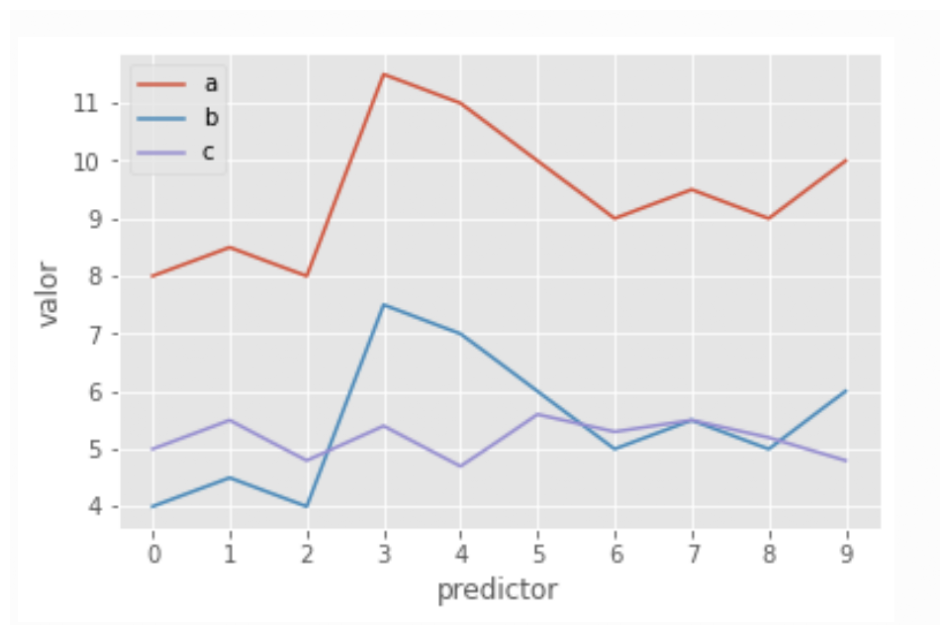

In [52]:
# reading png image file 
# importing pyplot and image from matplotlib 
import matplotlib.pyplot as plt 
import matplotlib.image as img 
im = img.imread('Captura de pantalla41.png') 
  # show image 
plt.figure(figsize=(12, 12))  # Cambia los valores para ajustar el tamaño deseado
plt.axis('off')
plt.imshow(im)
plt.show()

Este ejemplo pone de manifiesto que no existe una única medida de distancia que sea mejor que las demás, sino que depende del contexto en el que se utilice.

#### Correlación Jackknife


El coeficiente de correlación de Pearson resulta efectivo como medida de similitud en ámbitos muy diversos. Sin embargo, tiene la desventaja de no ser robusto frente a outliers, a pesar de que se cumpla la condición de normalidad. Si dos variables tienen un pico o un valle común en una única observación, por ejemplo, por un error de lectura, la correlación va a estar dominada por este registro a pesar de que entre las dos variables no exista correlación real. Lo mismo puede ocurrir en la dirección opuesta. Si dos variables están altamente correlacionadas excepto para una observación, en la que los valores son muy dispares, entonces la correlación existente quedará enmascarada. Una forma de evitarlo es recurrir a la Jackknife correlation, que consiste en calcular todos los posibles coeficientes de correlación entre dos variables si se excluye cada vez una de las observaciones. El promedio de todas las Jackknife correlations atenúa en cierta medida el efecto del outlier.

***Colocar ejemploy ecuaciones con Latex

Cuando se emplea este método, es conveniente calcular la diferencia entre el valor de correlación obtenido por Jackknife correlation  (𝜃¯)  y el que se obtiene si se emplean todas las observaciones  (𝑟¯) . A esta diferencia se le conoce como Bias. Su magnitud es un indicativo de cuanto está influenciada la estimación de la correlación entre dos variables debido a un valor atípico u outlier.

*** ecuacion sesgo 

Si se calcula la diferencia entre cada correlación  (𝑟̂𝑖)  estimada en el proceso de Jackknife y el valor de correlación  (𝑟̂)  obtenido si se emplean todas las observaciones, se puede identificar que observaciones son más influyentes.

Cuando el estudio requiere minimizar al máximo la presencia de falsos positivos, a pesar de que se incremente la de falsos negativos, se puede seleccionar como valor de correlación el menor de entre todos los calculados en el proceso de Jackknife.

Correlacion=min{𝑟̂1,𝑟̂2,...,𝑟̂𝑛}

A pesar de que el método de Jackknife permite aumentar la robustez de la correlación de Pearson, si los outliers son muy extremos su influencia seguirá siendo notable.

#### Simple matching coefficient

Cuando las variables con las que se pretende determinar la similitud entre observaciones son de tipo binario, a pesar de que es posible codificarlas de forma numérica como  1  o  0 , no tiene sentido aplicar operaciones aritméticas sobre ellas (media, suma...). Por ejemplo, si la variable sexo se codifica como  1  para mujer y  0 para hombre, carece de significado decir que la media de la variable sexo en un determinado set de datos es 0.5 . En situaciones como esta, no se pueden emplear medidas de similitud basadas en distancia euclídea, manhattan, correlación...

Dadas dos observaciones A y B, cada uno con  𝑛  atributos binarios, el simple matching coefficient (SMC) define la similitud entre ellos como:

*** ecuacion 

donde  𝑀00  y  𝑀11  son el número de variables para las que ambas observaciones tienen el mismo valor (ambas  0  o ambas  1 ), y  𝑀01  y  𝑀10  el número de variables que no coinciden. El valor de distancia simple matching distance (SMD) se corresponde con  1−𝑆𝑀𝐶 .


#### Índice Jaccard

ndice Jaccard o coeficiente de correlación Jaccard es similar al simple matching coefficient (SMC). La diferencia radica en que, el SMC, tiene el término  𝑀00  en el numerador y denominador, mientras que el índice de Jaccard no. Esto significa que SMC considera como coincidencias tanto si el atributo está presente en ambos sets como si el atributo no está en ninguno de los sets, mientras que Jaccard solo cuenta como coincidencias cuando el atributo está presente en ambos sets.

**** formula

o en términos matemáticos de sets:

**** formula

La distancia de Jaccard ( 1−𝐽 ) supera a la simple matching distance en aquellas situaciones en las que la coincidencia de ausencia no aporta información. Para ilustrar este hecho, supóngase que se quiere cuantificar la similitud entre dos clientes de un supermercado en base a los artículos comprados. Es de esperar que cada cliente solo adquiera unos pocos artículos de los muchos disponibles, por lo que el número de artículos no comprados por ninguno ( 𝑀00 ) será muy alto. Como la distancia de Jaccard ignora las coincidencias de tipo  𝑀00 , el grado de similitud dependerá únicamente de las coincidencias entre los artículos comprados.


#### Distancia coseno


El coseno del ángulo que forman dos vectores puede interpretarse como una medida de similitud de sus orientaciones, independientemente de sus magnitudes. Si dos vectores tienen exactamente la misma orientación (el ángulo que forman es 0º) su coseno toma el valor de 1, si son perpendiculares (forman un ángulo de 90º) su coseno es 0 y si tienen orientaciones opuestas (ángulo de 180º) su coseno es de -1.

In [ ]:
**** Formula 

Si los vectores se normalizan restandoles la media ( 𝑋−𝑋¯ ), la medida recibe el nombre de coseno centrado y es equivalente a la correlación de Pearson.

#### Escalado de las variables


La escala en la que se miden las variables y la magnitud de su varianza pueden afectar a los resultados obtenidos por clustering. Si una variable tiene una escala mucho mayor que el resto, determinará en gran medida el valor de distancia/similitud obtenido al comparar las observaciones, dirigiendo así la agrupación final. Escalar y centrar las variables antes de calcular la matriz de distancias para que tengan media 0 y desviación estándar 1, asegura que todas las variables tengan el mismo peso cuando se realice el clustering.

La forma más utilizada para escalar y centrar las variables es:

𝑥𝑖−𝑚𝑒𝑎𝑛(𝑥)𝑠𝑑(𝑥)


Aplicando esta transformación, existe una relación entre la distancia euclídea y la correlación de Pearson que hace que los resultados obtenidos por clustering sean equivalentes.

𝑑𝑒𝑢𝑐𝑙í𝑑𝑒𝑎(𝑝,𝑞 𝑒𝑠𝑡𝑎𝑛𝑑𝑎𝑟𝑖𝑧𝑎𝑑𝑜𝑠)=2𝑛(1−𝑐𝑜𝑟(𝑝,𝑞))‾‾‾‾‾‾‾‾‾‾‾‾‾‾‾√

#### Ejemplo cálculo distancias


El set de datos USArrests contiene el porcentaje de asaltos (Assault), asesinatos (Murder) y secuestros (Rape) por cada 100,000 habitantes para cada uno de los 50 estados de USA (1973). Además, también incluye el porcentaje de la población de cada estado que vive en zonas rurales (UrbanPoP). Empleando estas variables, se pretende calcular una matriz de distancias que permita identificar los estados más similares.

Dos de las librerías de python que implementan las distancias descritas en este documento (junto con otras) son sklearn.metrics.pairwise_distances y scipy.spatial.distance. En concreto, sklearn permite calcular las distancias: ‘cityblock’, ‘cosine’, ‘euclidean’, ‘l1’, ‘l2’, ‘manhattan’, ‘braycurtis’, ‘canberra’, ‘chebyshev’, ‘correlation’, ‘dice’, ‘hamming’, ‘jaccard’, ‘kulsinski’, ‘mahalanobis’, ‘minkowski’, ‘rogerstanimoto’, ‘russellrao’, ‘seuclidean’, ‘sokalmichener’, ‘sokalsneath’, ‘sqeuclidean’ y ‘yule’.


#### Librerias



In [106]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
import statsmodels.api as sm

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib.font_manager
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.metrics import pairwise_distances
from sklearn.preprocessing import scale

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

In [110]:
USArrests = sm.datasets.get_rdataset("USArrests", "datasets")
datos = USArrests.data
datos.head()


,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,13.2,236,58,21.2
Alaska,10.0,263,48,44.5
Arizona,8.1,294,80,31.0
Arkansas,8.8,190,50,19.5
California,9.0,276,91,40.6


##### Cálculo distancias

In [115]:
# Escalado de las variables
# ==============================================================================
datos_scaled = scale(X=datos, axis=0, with_mean=True, with_std=True) 
datos_scaled = pd.DataFrame(datos_scaled, columns=datos.columns, index=datos.index)
datos_scaled.head(4)

,Murder,Assault,UrbanPop,Rape
rownames,,,,
Alabama,1.255179,0.790787,-0.526195,-0.003451
Alaska,0.513019,1.118060,-1.224067,2.509424
Arizona,0.072361,1.493817,1.009122,1.053466
Arkansas,0.234708,0.233212,-1.084492,-0.186794


In [117]:
# Cálculo de distancias
# ==============================================================================
print('------------------')
print('Distancia euclídea')
print('------------------')
distancias = pairwise_distances(
                X      = datos_scaled,
                metric ='euclidean'
             )

# Se descarta la diagonal superior de la matriz
distancias[np.triu_indices(n=distancias.shape[0])] = np.nan

distancias = pd.DataFrame(
                distancias,
                columns=datos_scaled.index,
                index = datos_scaled.index
            )

distancias.iloc[:4,:4]

------------------
Distancia euclídea
------------------


rownames,Alabama,Alaska,Arizona,Arkansas
rownames,,,,
Alabama,NaN,NaN,NaN,NaN
Alaska,2.731204,NaN,NaN,NaN
Arizona,2.316805,2.728061,NaN,NaN
Arkansas,1.302905,2.854730,2.74535,NaN


Se reestructura la matriz de distancias para poder ordenar los pares de observaciones por orden de distancia.

In [120]:
# Top n observaciones más similares
# ==============================================================================
distancias.melt(ignore_index=False, var_name="estado_b", value_name='distancia') \
    .rename_axis("estado_a") \
    .reset_index() \
    .dropna() \
    .sort_values('distancia') \
    .head(3)

,estado_a,estado_b,distancia
728,New Hampshire,Iowa,0.207944
631,New York,Illinois,0.353774
665,Kansas,Indiana,0.433124


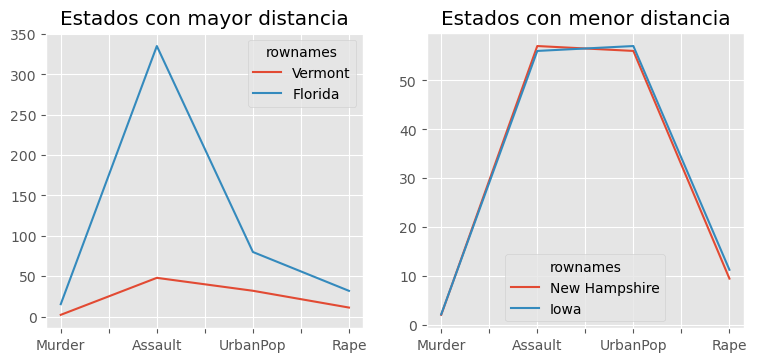

In [122]:
# Estados con mayor y menor distancia
# ==============================================================================
fig, axs = plt.subplots(1,2, figsize=(9, 3.84))
datos.loc[['Vermont', 'Florida']].transpose().plot(ax= axs[0])
axs[0].set_title('Estados con mayor distancia')
datos.loc[['New Hampshire', 'Iowa']].transpose().plot(ax= axs[1])
axs[1].set_title('Estados con menor distancia');

#### Número óptimo de clusters

Determinar el número óptimo de clusters es uno de los pasos más complicados a la hora de aplicar métodos de clustering, sobre todo cuando se trata de partitioning clustering, donde el número se tiene que especificar antes de poder ver los resultados. No existe una forma única de averiguar el número adecuado de clusters. Es un proceso bastante subjetivo que depende en gran medida del algoritmo empleado y de si se dispone de información previa sobre los datos con los que se está trabajando. A pesar de ello, se han desarrollado varias estrategias que ayudan en el proceso.



##### Método Elbow


El método Elbow, también conocido como método del codo, sigue una estrategia comúnmente empleada para encontrar el valor óptimo de un hiperparámetro. La idea es probar un rango de valores del hiperparámetro en cuestión, representar gráficamente los resultados obtenidos con cada uno, e identificar aquel punto de la curva (codo) a partir del cual la mejora deja de ser notable. En los casos de partitioning clustering, como por ejemplo K-means, las observaciones se agrupan de una forma tal que se minimiza la varianza total intra-cluster. El método Elbow calcula la varianza total intra-cluster en función del número de clusters y escoge como óptimo aquel valor a partir del cual añadir más clusters apenas consigue mejoría.

##### Método average silhouette


El método de average silhouette considera como número óptimo de clusters aquel que maximiza la media del silhouette coeficient de todas las observaciones.

El silhouette coeficient  (𝑠𝑖)  cuantifica cómo de buena es la asignación que se ha hecho de una observación comparando su similitud con el resto de observaciones de su cluster frente a las de los otros clusters. Su valor puede estar entre -1 y 1, siendo valores próximos a 1 un indicativo de que la observación se ha asignado al cluster correcto.

Para cada observación  𝑖 , el silhouette coeficient  (𝑠𝑖)  se obtiene del siguiente modo:

Calcular el promedio de las distancias (llámese  𝑎𝑖 ) entre la observación  𝑖  y el resto de observaciones que pertenecen al mismo cluster. Cuanto menor sea  𝑎𝑖 , mejor ha sido la asignación de  𝑖  a su cluster.

Calcular la distancia promedio entre la observación  𝑖  y el resto de clusters. Entendiendo por distancia promedio entre  𝑖  y un determinado cluster  𝐶  como la media de las distancias entre  𝑖  y las observaciones del cluster  𝐶 .

Identificar como  𝑏𝑖  a la menor de las distancias promedio entre  𝑖  y el resto de clusters, es decir, la distancia al cluster más próximo (neighbouring cluster).

Calcular el valor de silhouette como:

****formula 

Se considera como número óptimo de clusters aquel que maximiza la media del silhouette coeficient de todas las observaciones.

#### Estadístico gap


El estadístico gap fue publicado por R.Tibshirani, G.Walther y T. Hastie, autores también del magnífico libro Introduction to Statistical Learning. Este estadístico compara, para diferentes valores de k, la varianza total intra-cluster observada frente al valor esperado acorde a una distribución uniforme de referencia. La estimación del número óptimo de clusters es el valor k con el que se consigue maximizar el estadístico gap, es decir, encuentra el valor de k con el que se consigue una estructura de clusters lo más alejada posible de una distribución uniforme aleatoria. Este método puede aplicarse a cualquier tipo de clustering.

El algoritmo del gap statistic method es el siguiente:



Hacer clustering de los datos para un rango de valores de  𝑘  ( 𝑘=1 , ...,  𝐾=𝑛 ) y calcular para cada uno el valor de la varianza total intra-cluster ( 𝑊𝑘 ).

Simular  𝐵  sets de datos de referencia, todos ellos con una distribución aleatoria uniforme. Aplicar clustering a cada uno de los sets con el mismo rango de valores  𝑘  empleado en los datos originales, y calculando en cada caso la varianza total intra-cluster ( 𝑊𝑘𝑏 ). Se recomienda emplear valores de  𝐵=500 .

Calcular el estadístico gap para cada valor de  𝑘  como la desviación de la varianza observada  𝑊𝑘  respecto del valor esperado acorde a la distribución de referencia ( 𝑊𝑘𝑏 ). Calcular también su desviación estándar.

**** Formula 

Identificar el número de clusters óptimo como el menor de los valores  𝑘  para el que el estadístico gap se aleja menos de una desviación estándar del valor gap del siguiente  𝑘 :

**** formula

Los métodos Elbow, Silhouette y gap no tienen por qué coincidir exactamente en su estimación del número óptimo de clusters, pero tienden a acotar el rango de posibles valores. Por esta razón es recomendable calcular los tres y en función de los resultados decidir.


##### K-means

El algoritmo K-means (MacQueen, 1967) agrupa las observaciones en un número predefinido de K clusters de forma que, la suma de las varianzas internas de los clusters, sea lo menor posible. La implementación estándar de K-means (la de scikit-learn, MATLAB, R, etc.) usa exclusivamente la distancia euclídea.
Esto no es casualidad: el algoritmo se basa en minimizar la varianza intra-cluster, es decir, la suma de distancias cuadradas a la media del cluster. Y la media (centroide) solo tiene sentido en el espacio euclídeo porque minimiza esa suma de cuadrados.

Existen varias implementaciones de este algoritmo, la más común de ellas se conoce como Lloyd’s. En la bibliografía es común encontrar los términos inertia, within-cluster sum-of-squares o varianza intra-cluster para referirse a la varianza interna de los clusters.

##### Explicacion del algoritmo.

Considérense  𝐶1 ,...,  𝐶𝐾  como los sets formados por los índices de las observaciones de cada uno de los clusters. Por ejemplo, el set  𝐶1  contiene los índices de las observaciones agrupadas en el cluster 1. La nomenclatura empleada para indicar que la observación  𝑖  pertenece al cluster  𝑘  es:  𝑖∈𝐶𝑘 . Todos los sets satisfacen dos propiedades:

𝐶1∪𝐶2∪...∪𝐶𝐾={1,...,𝑛} . Significa que toda observación pertenece a uno de los K clusters.

𝐶𝑘∩𝐶𝑘′=∅  para todo  𝑘≠𝑘′ . Implica que los clusters no solapan, ninguna observación pertenece a más de un cluster a la vez.

Dos de las medidas comúnmente empleadas para cuantificar la varianza interna de un cluster ( 𝑊(𝐶𝑘) ) son:

La suma de las distancias euclídeas al cuadrado entre cada observación ( 𝑥𝑖 ) y el centroide ( 𝜇 ) de su cluster. Esto equivale a la suma de cuadrados internos del cluster y es la métrica que utiliza scikitlearn.

***formula 

La suma de las distancias euclídeas al cuadrado entre todos los pares de observaciones que forman el cluster, dividida entre el número de observaciones del cluster.

**** Formula 

Minimizar la suma total de varianza interna  ∑𝑘𝑘=1𝑊(𝐶𝑘)  de forma exacta (encontrar el mínimo global) es un proceso muy complejo debido a la inmensa cantidad de formas en las que n observaciones se pueden repartir en K grupos. En lugar de esto, k-means trata de encontrar una solución que, aun no siendo la mejor de entre todas las posibles, sea buena (óptimo local). El algoritmo empleado es:

Especificar el número K de clusters que se quieren crear.

1. Seleccionar de forma aleatoria k observaciones del set de datos como centroides iniciales.

2. Asignar cada una de las observaciones al centroide más cercano.

3. Para cada uno de los K clusters generados en el paso 3, recalcular su centroide.

4. Repetir los pasos 3 y 4 hasta que las asignaciones no cambien o se alcance el número máximo de iteraciones establecido.



Este algoritmo garantiza que, en cada paso, se reduzca la intra-varianza total de los clusters hasta alcanzar un óptimo local. Debido a que el algoritmo de K-means no evalúa todas las posibles distribuciones de las observaciones sino solo parte de ellas, los resultados obtenidos dependen de la asignación aleatoria inicial (paso 2). Por esta razón, es importante ejecutar el algoritmo varias veces (25-50), cada una con una asignación aleatoria inicial distinta, y seleccionar aquella que haya conseguido una menor varianza total.


Ventajas y desventajas


- K-means es uno de los métodos de clustering más utilizados. Destaca por la sencillez y velocidad de su algoritmo, sin embargo, presenta una serie de limitaciones que se deben tener en cuenta.

- Requiere que se indique de antemano el número de clusters que se van a crear. Esto puede ser complicado si no se dispone de información adicional sobre los datos con los que se trabaja. Se han desarrollado varias estrategias para ayudar a identificar potenciales valores óptimos de K (elbow, shilouette), pero todas ellas son orientativas.

- Dificultad para detectar clusters alargados o con formas irregulares.

- Las agrupaciones resultantes pueden variar dependiendo de la asignación aleatoria inicial de los centroides. Para minimizar este problema, se recomienda repetir el proceso de clustering entre 25-50 veces y seleccionar como resultado definitivo el que tenga menor suma total de varianza interna. Aun así, solo se puede garantizar la reproducibilidad de los resultados si se emplean semillas.

- Presenta problemas de robustez frente a outliers. La única solución es excluirlos o recurrir a otros métodos de clustering más robustos como K-medoids (PAM).

#### Ejemplo. Simulacion


Los siguientes datos simulados contienen observaciones que pertenecen a cuatro grupos distintos. Se pretende aplicar K-means-clustering con el objetivo de identificar las agrupaciones reales.

Librerías

Las librerías utilizadas en este ejemplo son:

In [163]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.cluster import KMeans
from sklearn.preprocessing import scale
from sklearn.metrics import silhouette_score

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

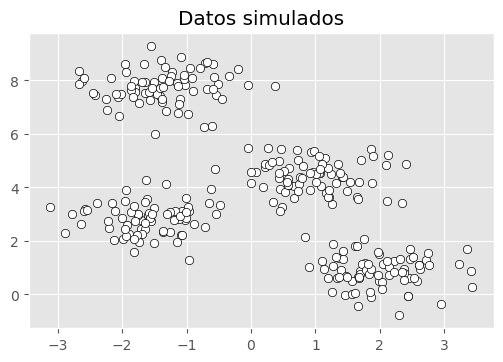

In [165]:
# Simulación de datos
# ==============================================================================
X, y = make_blobs(
        n_samples    = 300, 
        n_features   = 2, 
        centers      = 4, 
        cluster_std  = 0.60, 
        shuffle      = True, 
        random_state = 0
       )

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.scatter(
    x = X[:, 0],
    y = X[:, 1], 
    c = 'white',
    marker    = 'o',
    edgecolor = 'black', 
)
ax.set_title('Datos simulados');

#### Modelo Kmeans

-Con la clase sklearn.cluster.KMeans de Scikit-Learn se pueden entrenar modelos de clustering utilizando el algoritmo k-means. Entre sus parámetros destacan:

-n_clusters: determina el número  𝐾  de clusters que se van a generar.

-init: estrategia para asignar los centroides iniciales. Por defecto se emplea 'k-means++', una estrategia que trata de alejar los centroides lo máximo posible facilitando la convergencia. Sin embargo, esta estrategia puede ralentizar el proceso cuando hay muchos datos, si esto ocurre, es mejor utilizar 'random'.

-n_init: determina el número de veces que se va a repetir el proceso, cada vez con una asignación aleatoria inicial distinta. Es recomendable que este último valor sea alto, entre 10-25, para no obtener resultados subóptimos debido a una iniciación poco afortunada del proceso.

-max_iter: número máximo de iteraciones permitidas.

-random_state: semilla para garantizar la reproducibilidad de los resultados.

In [168]:
# Escalado de datos
# ==============================================================================
X_scaled = scale(X)

In [170]:
# Modelo
# ==============================================================================
X_scaled = scale(X)
modelo_kmeans = KMeans(n_clusters=4, n_init=25, random_state=123)
modelo_kmeans.fit(X=X_scaled)

,n_clusters,4
,init,'k-means++'
,n_init,25
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,123
,copy_x,True
,algorithm,'lloyd'


El objeto devuelto por KMeans() contiene entre otros datos: la media de cada una de las variables para cada cluster (cluster_centers_), es decir, los centroides. Un vector indicando a qué cluster se ha asignado cada observación (.labels_) y la suma total de cuadrados internos de todos los clusters (.inertia_).

##### Número de clusters

Al tratarse de una simulación, se conoce el verdadero número de grupos (4) y a cuál de ellos pertenece cada observación. Esto no sucede en la mayoría de casos prácticos, pero es útil como ejemplo ilustrativo cómo funciona K-means.

In [174]:
# Clasificación con el modelo kmeans
# ==============================================================================
y_predict = modelo_kmeans.predict(X=X_scaled)

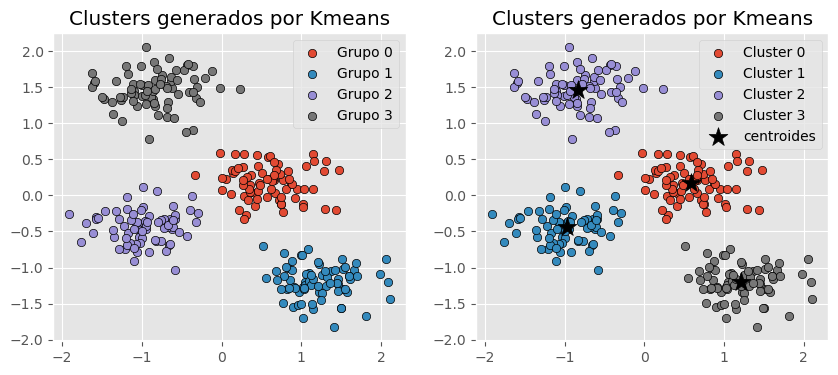

In [176]:
# Representación gráfica: grupos originales vs clusters creados
# ==============================================================================
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Grupos originales
for i in np.unique(y):
    ax[0].scatter(
        x = X_scaled[y == i, 0],
        y = X_scaled[y == i, 1], 
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black', 
        label= f"Grupo {i}"
    )
    
ax[0].set_title('Clusters generados por Kmeans')
ax[0].legend();

for i in np.unique(y_predict):
    ax[1].scatter(
        x = X_scaled[y_predict == i, 0],
        y = X_scaled[y_predict == i, 1], 
        c = plt.rcParams['axes.prop_cycle'].by_key()['color'][i],
        marker    = 'o',
        edgecolor = 'black', 
        label= f"Cluster {i}"
    )
    
ax[1].scatter(
    x = modelo_kmeans.cluster_centers_[:, 0],
    y = modelo_kmeans.cluster_centers_[:, 1], 
    c = 'black',
    s = 200,
    marker = '*',
    label  = 'centroides'
)
ax[1].set_title('Clusters generados por Kmeans')
ax[1].legend();

Este tipo de visualización es muy útil e informativa, sin embargo, solo es posible cuando se trabaja con dos dimensiones. Si los datos contienen más de dos variables (dimensiones), una posible solución es utilizar las dos primeras componentes principales obtenidas con un PCA previo.

El número de aciertos y errores puede representarse en modo de matriz de confusión. A la hora de interpretar estas matrices, es importante recordar que el clustering asigna las observaciones a clusters cuyo identificador no tiene porqué coincidir con la nomenclatura empleada para los grupos reales. En este ejemplo, el grupo 1 se ha asignado al cluster 3. Así pues, por cada fila de la matriz cabe esperar un valor alto (coincidencias) para una de las posiciones y valores bajos en las otras (errores de clasificación), pero no tienen por qué coincidir los nombres (diagonal).

In [179]:
# Matriz de confusión: grupos originales vs clusters creados
# ==============================================================================
pd.crosstab(y, y_predict, dropna=False, rownames=['grupo_real'], colnames=['cluster'])

cluster,0,1,2,3
grupo_real,,,,
0,75,0,0,0
1,0,0,0,75
2,0,75,0,0
3,0,0,75,0


En este análisis, todas las observaciones se han clasificado correctamente. De nuevo repetir que, en la realidad, no se suelen conocer los verdaderos grupos en los que se dividen las observaciones, de lo contrario no se necesitaría aplicar clustering.

Supóngase ahora que se trata de un caso real, en el que se desconoce el número de grupos en los que se subdividen las observaciones. El analista tendría que probar con diferentes valores de  𝐾  y decidir cuál parece más razonable. A continuación, se muestran los resultados para  𝐾=2  y  𝐾=6 .

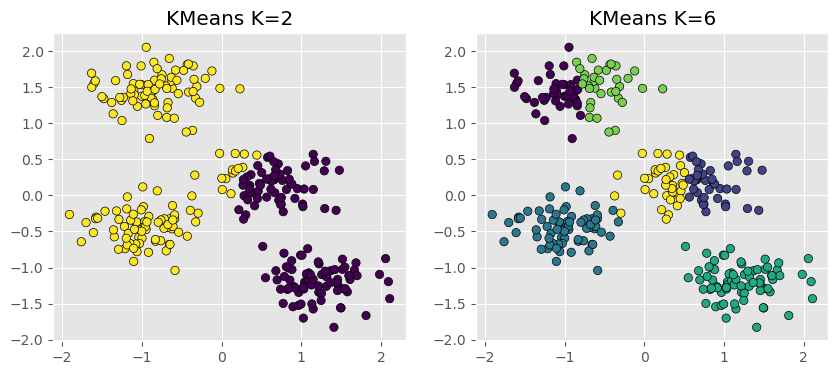

In [187]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))

# Resultados para K = 2
# ==============================================================================
y_predict = KMeans(n_clusters=2, n_init=25, random_state=123).fit_predict(X=X_scaled)
ax[0].scatter(
        x = X_scaled[:, 0],
        y = X_scaled[:, 1], 
        c = y_predict,
        #cmap='viridis',
        marker    = 'o',
        edgecolor = 'black'
    )
ax[0].set_title('KMeans K=2');

# Resultados para K = 6
# ==============================================================================
y_predict = KMeans(n_clusters=6, n_init=25, random_state=123).fit_predict(X=X_scaled)
ax[1].scatter(
        x = X_scaled[:, 0],
        y = X_scaled[:, 1], 
        c = y_predict,
        #cmap='viridis',
        marker    = 'o',
        edgecolor = 'black'
    )
ax[1].set_title('KMeans K=6');

Al observar los resultados obtenidos para K = 2, es intuitivo pensar que el grupo que se encuentra entorno a las coordenadas 𝑥=0.5,𝑦=0  (mayoritariamente considerado como amarillo) debería ser un grupo separado. Para K = 6 no parece muy razonable la separación de los grupos amarillo y azul. Este ejemplo muestra la principal limitación del método de K-means, el hecho de tener que escoger de antemano el número de clusters que se generan.

La deducción anterior solo puede hacerse visualmente cuando se trata de dos dimensiones. Una forma sencilla de estimar el número K óptimo de clusters cuando no se dispone de esta información, es aplicar el algoritmo de K-means para un rango de valores de K e identificar aquel valor a partir del cual la reducción en la suma total de varianza intra-cluster (inertia) deja de ser sustancial. A esta estrategia se la conoce como método del codo o elbow method.

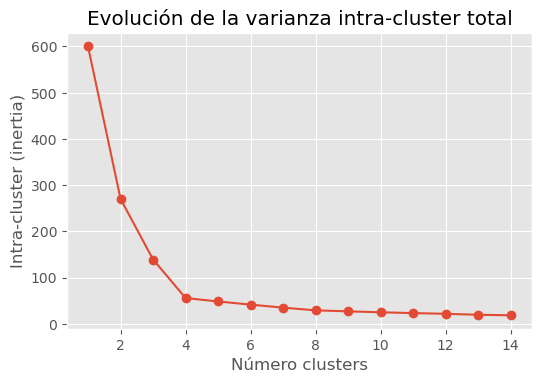

In [190]:
# Método elbow para identificar el número óptimo de clusters
# ==============================================================================
range_n_clusters = range(1, 15)
inertias = []

for n_clusters in range_n_clusters:
    modelo_kmeans = KMeans(
                        n_clusters   = n_clusters, 
                        n_init       = 20, 
                        random_state = 123
                    )
    modelo_kmeans.fit(X_scaled)
    inertias.append(modelo_kmeans.inertia_)

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, inertias, marker='o')
ax.set_title("Evolución de la varianza intra-cluster total")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Intra-cluster (inertia)');


A partir de 4 clusters la reducción en la suma total de cuadrados internos parece estabilizarse, indicando que K = 4 es una buena opción.

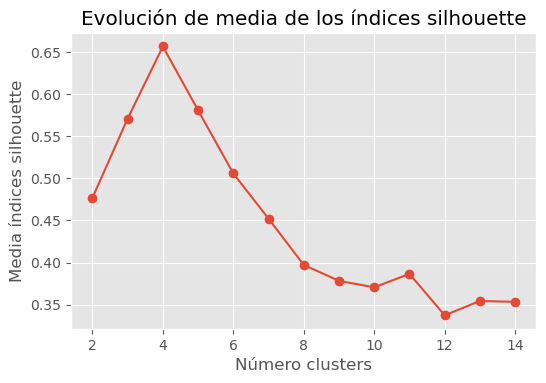

In [193]:
# Método silhouette para identificar el número óptimo de clusters
# ==============================================================================
range_n_clusters = range(2, 15)
valores_medios_silhouette = []

for n_clusters in range_n_clusters:
    modelo_kmeans = KMeans(
                        n_clusters   = n_clusters, 
                        n_init       = 20, 
                        random_state = 123
                    )
    cluster_labels = modelo_kmeans.fit_predict(X_scaled)
    silhouette_avg = silhouette_score(X_scaled, cluster_labels)
    valores_medios_silhouette.append(silhouette_avg)
    
fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.plot(range_n_clusters, valores_medios_silhouette, marker='o')
ax.set_title("Evolución de media de los índices silhouette")
ax.set_xlabel('Número clusters')
ax.set_ylabel('Media índices silhouette');

El valor medio de los índices silhouette se maximiza con 4 clusters. Acorde a este criterio, K = 4 es la mejor opción.

Ambos criterios, elbow y silhouette, identifican el valor K= como valor óptimo de clusters.

#### K-medoids

K-medoids es un método de clustering muy similar a K-means en cuanto a que ambos agrupan las observaciones en K clusters, donde K es un valor preestablecido por el analista. La diferencia es que, en K-medoids, cada cluster está representado por una observación presente en el cluster (medoid), mientras que en K-means cada cluster está representado por su centroide, que se corresponde con el promedio de todas las observaciones del cluster pero con ninguna en particular.

Una definición más exacta del término medoid es: elemento dentro de un cluster cuya distancia (diferencia) promedio entre él y todos los demás elementos del mismo cluster es lo menor posible. Se corresponde con el elemento más central del cluster y por lo tanto puede considerarse como el más representativo. El hecho de utilizar medoids en lugar de centroides hace de K-medoids un método más robusto que K-means, viéndose menos afectado por outliers o ruido. A modo de idea intuitiva puede considerarse como la analogía entre media y mediana.

El algoritmo más empleado para aplicar K-medoids se conoce como PAM (Partitioning Around Medoids) y sigue los siguientes pasos:

1. Seleccionar K observaciones aleatorias como medoids iniciales. También es posible identificarlas de forma específica.

2. Calcular la matriz de distancia entre todas las observaciones si esta no se ha calculado anteriormente.

3. Asignar cada observación a su medoid más cercano.

4. Para cada uno de los clusters creados, comprobar si seleccionando otra observación como medoid se consigue reducir la distancia promedio del cluster, si esto ocurre, seleccionar la observación que consigue una mayor reducción como nuevo medoid.

5. Si al menos un medoid ha cambiado en el paso 4, volver al paso 3, de lo contrario, se termina el proceso.



A diferencia del algoritmo K-means, en el que se minimiza la suma total de cuadrados intra-cluster (suma de las distancias al cuadrado de cada observación respecto a su centroide), el algoritmo K-medoids minimiza la suma de las diferencias de cada observación respecto a su medoid.

Por lo general, el método de K-medoids se utiliza cuando se conoce o se sospecha de la presencia de outliers. Si esto ocurre, es recomendable utilizar como medida de similitud la distancia de Manhattan, ya que es menos sensible a outliers que la euclídea.

#### Ventajas y desventajas

- K-medoids es un método de clustering más robusto que K-means, por lo es más adecuado cuando el set de datos contiene outliers o ruido.

- Al igual que K-means, necesita que se especifique de antemano el número de clusters que se van a crear. Esto puede ser complicado de determinar si no se dispone de información adicional sobre los datos. Muchas de las estrategias empleadas en K-means para identificar el número óptimo, pueden aplicarse en K-medoids.

- Para sets de datos grandes se necesitan muchos recursos computacionales. En tal situación se recomienda aplicar el método CLARA.


El algoritmo K-medoids está implementado en la clase KMedoids de la librería sklearn_extra. Su funcionamiento es análogo al descrito en el apartado de K-means. También está disponible en la librería PyClustering.


#### Hierarchical clustering

Hierarchical clustering es una alternativa a los métodos de partitioning clustering que no requiere que se pre-especifique el número de clusters. Los métodos que engloba el hierarchical clustering se subdividen en dos tipos dependiendo de la estrategia seguida para crear los grupos:

Aglomerativo (agglomerative clustering o bottom-up): el agrupamiento se inicia con todas las observaciones separadas, cada una formando un cluster individual. Los clusters se van combinado a medida que la estructura crece hasta converger en uno solo.

Divisivo (divisive clustering o top-down): es la estrategia opuesta al aglomerativo. Se inicia con todas las observaciones contenidas en un mismo cluster y se suceden divisiones hasta que cada observación forma un cluster* individual.

En ambos casos, los resultados pueden representarse de forma muy intuitiva en una estructura de árbol llamada dendrograma.

#### Aglomerativo

El algoritmo seguido para por el clustering aglomerativo es:

1. Considerar cada una de las n observaciones como un cluster individual, formando así la base del dendrograma (hojas).

2. Proceso iterativo hasta que todas las observaciones pertenecen a un único cluster:

- 2.1 Calcular la distancia entre cada posible par de los n clusters. El investigador debe determinar el tipo de medida empleada para cuantificar la similitud entre observaciones o grupos (distancia y linkage).

- 2.2 Los dos clusters más similares se fusionan, de forma que quedan n-1 clusters.

3. Cortar la estructura de árbol generada (dendrograma) a una determinada altura para crear los clusters finales.



Para que el proceso de agrupamiento pueda llevarse a cabo tal como indica el algoritmo anterior, es necesario definir cómo se cuantifica la similitud entre dos clusters. Es decir, se tiene que extender el concepto de distancia entre pares de observaciones para que sea aplicable a pares de grupos, cada uno formado por varias observaciones. A este proceso se le conoce como linkage. A continuación, se describen los 5 tipos de linkage más empleados y sus definiciones.

- Complete or Maximum: se calcula la distancia entre todos los posibles pares formados por una observación del cluster A y una del cluster B. La mayor de todas ellas se selecciona como la distancia entre los dos clusters. Se trata de la medida más conservadora (maximal intercluster dissimilarity).

- Single or Minimum: se calcula la distancia entre todos los posibles pares formados por una observación del cluster A y una del cluster B. La menor de todas ellas se selecciona como la distancia entre los dos clusters. Se trata de la medida menos conservadora (minimal intercluster dissimilarity).

- Average: Se calcula la distancia entre todos los posibles pares formados por una observación del cluster A y una del cluster B. El valor promedio de todas ellas se selecciona como la distancia entre los dos clusters (mean intercluster dissimilarity).

- Centroid: Se calcula el centroide de cada uno de los clusters y se selecciona la distancia entre ellos como la distancia entre los dos clusters.

- Ward: Se trata de un método general. La selección del par de clusters que se combinan en cada paso del agglomerative hierarchical clustering se basa en el valor óptimo de una función objetivo, pudiendo ser esta última cualquier función definida por el analista. El método Ward's minimum variance es un caso particular en el que el objetivo es minimizar la suma total de varianza intra-cluster. En cada paso, se identifican aquellos 2 clusters cuya fusión conlleva menor incremento de la varianza total intra-cluster. Esta es la misma métrica que se minimiza en K-means.

Los métodos de complete, average y Ward's minimum variance suelen ser los preferidos por los analistas debido a que generan dendrogramas más compensados. Sin embargo, no se puede determinar que uno sea mejor que otro, ya que depende del caso de estudio en cuestión. Por ejemplo, en genómica, se emplea con frecuencia el método de centroides. Junto con los resultados de un proceso de hierarchical clustering siempre hay que indicar qué distancia se ha empleado, así como el tipo de linkage, ya que, dependiendo de estos, los resultados pueden variar en gran medida.

#### Divisivo

El algoritmo más conocido de divisive hierarchical clustering es DIANA (DIvisive ANAlysis Clustering). Este algoritmo se inicia con un único cluster que contiene todas las observaciones. A continuación, se van sucediendo divisiones hasta que cada observación forma un cluster independiente. En cada iteración, se selecciona el cluster con mayor diámetro, entendiendo por diámetro de un cluster la mayor de las diferencias entre dos de sus observaciones. Una vez seleccionado el cluster, se identifica la observación más dispar, que es aquella con mayor distancia promedio respecto al resto de observaciones que forman el cluster. Esta observación inicia el nuevo cluster. Se reasignan las observaciones en función de si están más próximas al nuevo cluster o al resto de la partición, dividiendo así el cluster seleccionado en dos nuevos clusters.

1. Todas las n observaciones forman un único cluster.

2. Repetir hasta que haya n clusters:

2.1 Calcular para cada cluster la mayor de las distancias entre pares de observaciones (diámetro del cluster).

2.2 Seleccionar el cluster con mayor diámetro.

2.3 Calcular la distancia media de cada observación respecto a las demás.

2.4 La observación más distante inicia un nuevo cluster.

2.5 Se reasignan las observaciones restantes al nuevo cluster o al viejo dependiendo de cuál está más próximo.



A diferencia del clustering aglomerativo, en el que hay que elegir un tipo de distancia y un método de linkage, en el clustering divisivo solo hay que elegir la distancia, no hay linkage

#### Dendrograma

Los resultados del hierarchical clustering pueden representarse como un árbol en el que las ramas representan la jerarquía con la que se van sucediendo las uniones de clusters.

Supóngase que se dispone de 45 observaciones en un espacio de dos dimensiones, a los que se les aplica hierarchical clustering para intentar identificar grupos. El siguiente dendrograma representa los resultados obtenidos.

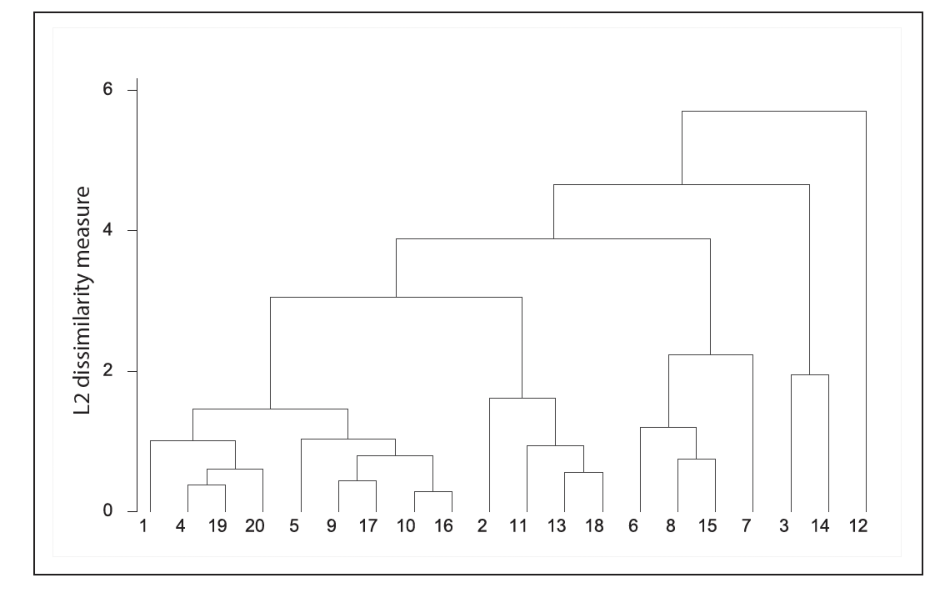

In [227]:
# reading png image file 
# importing pyplot and image from matplotlib 
import matplotlib.pyplot as plt 
import matplotlib.image as img 
im = img.imread('Captura43.png') 
  # show image 
plt.figure(figsize=(12, 12))  # Cambia los valores para ajustar el tamaño deseado
plt.axis('off')
plt.imshow(im)
plt.show()

Por ejemplo, la observación 4 (8) es la más similar a la 19 (10) ya que es la primera fusión que recibe la observación 19 (10) (y viceversa). Podría resultar tentador decir que la observación 5, situada inmediatamente a la derecha de la 10, es la siguiente más similar, sin embargo, las observaciones 1 (28)y 20 (44) son más similares a la 19 a pesar de que se encuentran más alejadas en el eje horizontal. 

#### Cortar el dendograma para generar los clusters


Además de representar en un dendrograma la similitud entre observaciones, se tiene que identificar el número de clusters creados y qué observaciones forman parte de cada uno. Si se realiza un corte horizontal a una determinada altura del dendrograma, el número de ramas que sobrepasan (en sentido ascendente) dicho corte se corresponde con el número de clusters. La siguiente imagen muestra dos veces el mismo dendrograma. La altura de corte tiene por lo tanto la misma función que el valor K en K-means-clustering: controla el número de clusters obtenidos.

Con un solo dendrograma se dispone de la flexibilidad para generar cualquier número de clusters desde 1 a n. La selección del número óptimo puede valorarse de forma visual, tratando de identificar las ramas principales en base a la altura a la que ocurren las uniones. En el ejemplo expuesto es razonable elegir 6  clusters.

In [261]:
def plot_dendrogram(model, **kwargs):
    '''
    Esta función extrae la información de un modelo AgglomerativeClustering
    y representa su dendograma con la función dendogram de scipy.cluster.hierarchy
    '''
    
    counts = np.zeros(model.children_.shape[0])
    n_samples = len(model.labels_)
    for i, merge in enumerate(model.children_):
        current_count = 0
        for child_idx in merge:
            if child_idx < n_samples:
                current_count += 1  # leaf node
            else:
                current_count += counts[child_idx - n_samples]
        counts[i] = current_count

    linkage_matrix = np.column_stack([model.children_, model.distances_,
                                      counts]).astype(float)

    # Plot
    dendrogram(linkage_matrix, **kwargs)

In [263]:
# Modelos
from sklearn.cluster import AgglomerativeClustering
# ==============================================================================
modelo_hclust_complete = AgglomerativeClustering(
                            metric = 'euclidean',
                            linkage  = 'complete',
                            distance_threshold = 0,
                            n_clusters         = None
                        )
modelo_hclust_complete.fit(X=X_scaled)

modelo_hclust_average = AgglomerativeClustering(
                            metric = 'euclidean',
                            linkage  = 'average',
                            distance_threshold = 0,
                            n_clusters         = None
                        )
modelo_hclust_average.fit(X=X_scaled)

modelo_hclust_ward = AgglomerativeClustering(
                            metric = 'euclidean',
                            linkage  = 'ward',
                            distance_threshold = 0,
                            n_clusters         = None
                     )
modelo_hclust_ward.fit(X=X_scaled)

,n_clusters,None
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,0
,compute_distances,False


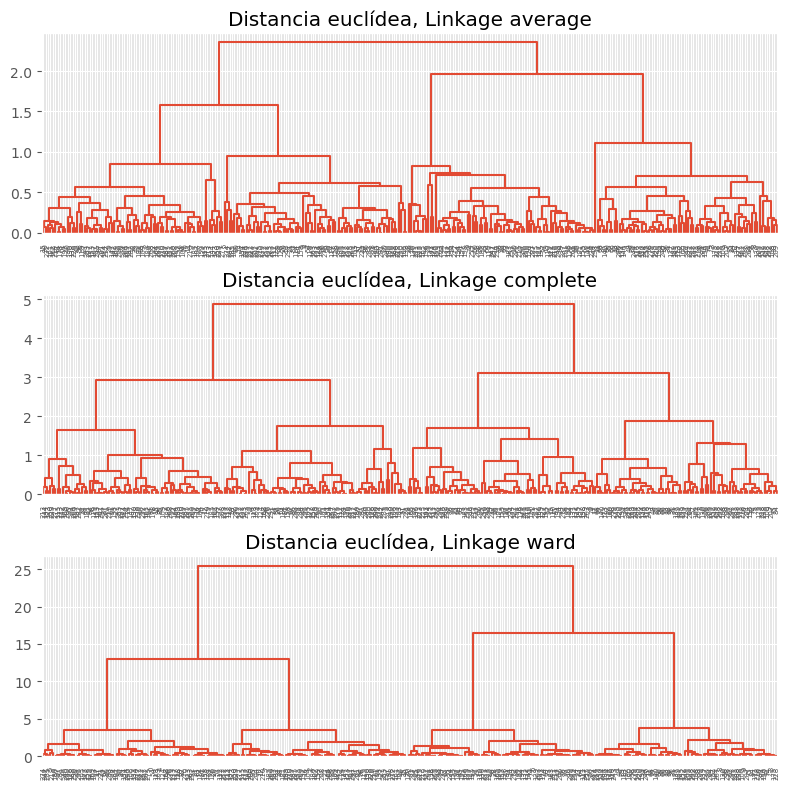

In [266]:
# Dendrogramas
# ==============================================================================
fig, axs = plt.subplots(3, 1, figsize=(8, 8))
plot_dendrogram(modelo_hclust_average, color_threshold=0, ax=axs[0])
axs[0].set_title("Distancia euclídea, Linkage average")
plot_dendrogram(modelo_hclust_complete, color_threshold=0, ax=axs[1])
axs[1].set_title("Distancia euclídea, Linkage complete")
plot_dendrogram(modelo_hclust_ward, color_threshold=0, ax=axs[2])
axs[2].set_title("Distancia euclídea, Linkage ward")
plt.tight_layout();

En este caso, los tres tipos de linkage identifican claramente 4 clusters, si bien esto no significa que en los 3 dendrogramas los clusters estén formados por exactamente las mismas observaciones.

#### Número de clusters

Una forma de identificar el número de clusters, es inspeccionar visualmente el dendograma y decidir a qué altura se corta para generar los clusters. Por ejemplo, para los resultados generados mediante distancia euclídea y linkage ward, parece sensato cortar el dendograma a una altura de entre 5 y 10, de forma que se creen 4 clusters.

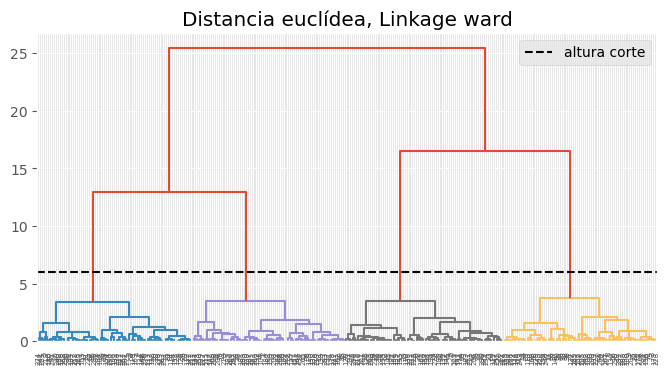

In [272]:
fig, ax = plt.subplots(1, 1, figsize=(8, 4))
altura_corte = 6
plot_dendrogram(modelo_hclust_ward, color_threshold=altura_corte, ax=ax)
ax.set_title("Distancia euclídea, Linkage ward")
ax.axhline(y=altura_corte, c = 'black', linestyle='--', label='altura corte')
ax.legend();


Otra forma de identificar potenciales valores óptimos para el número de clusters en modelos hierarchical clustering es mediante los índices silhouette

#### Density based clustering (DBSCAN)

Density-based spatial clustering of applications with noise (DBSCAN) fue presentado en 1996 por Ester et al. como una forma de identificar clusters siguiendo el modo intuitivo en el que lo hace el cerebro humano, identificando regiones con alta densidad de observaciones separadas por regiones de baja densidad.

El algoritmo DBSCAN necesita dos parámetros:

- Epsilon  (𝜖) : radio que define la región vecina a una observación, también llamada  𝜖 -neighborhood.

- Minimum points (min_samples): número mínimo de observaciones dentro de la región epsilon.

Empleando estos dos parámetros, cada observación del set de datos se puede clasificar en una de las siguientes tres categorías:

- Core point: observación que tiene en su  𝜖 -neighborhood un número de observaciones vecinas igual o mayor a min_samples.

- Border point: observación no satisface el mínimo de observaciones vecinas para ser core point pero que pertenece al  𝜖 -neighborhood de otra observación que sí es core point.

- Noise u outlier: observación que no es core point ni border point.

#### Algoritmo


1. Para cada observación  𝑥𝑖  calcular la distancia entre ella y el resto de observaciones. Si en su  𝜖 -neighborhood hay un número de observaciones  ≥𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠  marcar la observación como core point, de lo contrario marcarla como visitada.

2. Para cada observación  𝑥𝑖  marcada como core point, si todavía no ha sido asignada a ningún cluster, crear uno nuevo y asignarla a él. Encontrar recursivamente todas las observaciones densamente conectadas a ella y asignarlas al mismo cluster.

3. Iterar el mismo proceso para todas las observaciones que no hayan sido visitadas.

4. Aquellas observaciones que tras haber sido visitadas no pertenecen a ningún cluster se marcan como outliers

Como resultado, todo cluster cumple dos propiedades: todos los puntos que forman parte de un mismo cluster están densamente conectados entre ellos y, si una observación  𝐴  es densamente alcanzable desde cualquier otra observación de un cluster, entonces  𝐴  también pertenece al cluster.


####Hiperparámetros


Como ocurre en muchas otras técnicas estadísticas, en DBSCAN no existe una forma única y exacta de encontrar el valor adecuado de epsilon  (𝜖)  y  𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠 . A modo orientativo se pueden seguir las siguientes premisas:

- 𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠 : cuanto mayor sea el tamaño del set de datos, mayor debe ser el valor mínimo de observaciones vecinas. En el libro Practical Guide to Cluster Analysis in R recomiendan no bajar nunca de 3. Si los datos contienen niveles altos de ruido, aumentar  𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠  favorecerá la creación de clusters significativos menos influenciados por outliers.

- epsilon: una buena forma de escoger el valor de  𝜖  es estudiar las distancias promedio entre las  𝑘=𝑚𝑖𝑛𝑠𝑎𝑚𝑝𝑙𝑒𝑠 observaciones más próximas. Al representar estas distancias en función de  𝜖 , el punto de inflexión de la curva suele ser un valor óptimo. Si el valor de  𝜖  escogido es muy pequeño, una proporción alta de las observaciones no se asignarán a ningún cluster, por el contrario, si el valor es demasiado grande, la mayoría de observaciones se agruparán en un único cluster.




#### Ventajas

-No requiere que el usuario especifique el número de clusters.

-Es independiente de la forma que tengan los clusters.

-Puede identificar outliers, por lo que los clusters generados no se ven influenciados por ellos.


In [298]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import scale
from sklearn.metrics import silhouette_score

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

#### Datos

In [293]:
url = 'https://raw.githubusercontent.com/JoaquinAmatRodrigo/' \
      + 'Estadistica-machine-learning-python/master/data/multishape.csv'
datos = pd.read_csv(url)
datos.head()

,x,y,shape
0,-0.803739,-0.853053,1
1,0.852851,0.367618,1
2,0.927180,-0.274902,1
3,-0.752626,-0.511565,1
4,0.706846,0.810679,1


Con la clase sklearn.cluster.DBSCAN de Scikit-Learn se pueden entrenar modelos de clustering utilizando el algoritmo DBSCAN. Entre sus parámetros destacan:

-eps: .

-min_samples: .

-metric: métrica utilizada como distancia. Puede ser: “euclidean”, “l1”, “l2”, “manhattan”, “cosine”, or “precomputed”. Si se utiliza linkage=“ward”, solo se permite “euclidean”.

In [303]:
# Escalado de datos
# ==============================================================================
X = datos.drop(columns='shape').to_numpy()
X_scaled = scale(X)

In [305]:
# Modelo
# ==============================================================================
modelo_dbscan = DBSCAN(
                    eps          = 0.2,
                    min_samples  = 5,
                    metric       = 'euclidean',
                )

modelo_dbscan.fit(X=X_scaled)

,eps,0.2
,min_samples,5
,metric,'euclidean'
,metric_params,None
,algorithm,'auto'
,leaf_size,30
,p,None
,n_jobs,None


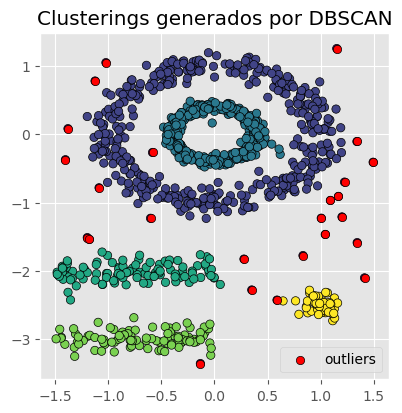

In [307]:
# Clasificación
# ==============================================================================
labels = modelo_dbscan.labels_

fig, ax = plt.subplots(1, 1, figsize=(4.5, 4.5))

ax.scatter(
    x = X[:, 0],
    y = X[:, 1], 
    c = labels,
    marker    = 'o',
    edgecolor = 'black'
)

# Los outliers se identifican con el label -1
ax.scatter(
    x = X[labels == -1, 0],
    y = X[labels == -1, 1], 
    c = 'red',
    marker    = 'o',
    edgecolor = 'black',
    label = 'outliers'
)

ax.legend()
ax.set_title('Clusterings generados por DBSCAN');

In [309]:
# Número de clusters y observaciones "outliers"
# ==============================================================================
n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
n_noise    = list(labels).count(-1)

print(f'Número de clusters encontrados: {n_clusters}')
print(f'Número de outliers encontrados: {n_noise}')

Número de clusters encontrados: 5
Número de outliers encontrados: 25


### Gaussian mixture models (GMMs)

Algoritmo


Un Gaussian Mixture model es un modelo probabilístico en el que se considera que las observaciones siguen una distribución probabilística formada por la combinación de múltiples distribuciones normales (componentes). En su aplicación al clustering, puede entenderse como una generalización de K-means con la que, en lugar de asignar cada observación a un único cluster, se obtiene una probabilidad de pertenencia a cada uno.

Para estimar los parámetros que definen la función de distribución de cada cluster (media y matriz de covarianza) se recurre al algoritmo de Expectation-Maximization (EM). Una vez aprendidos los parámetros, se puede calcular la probabilidad que tiene cada observación de pertenecer a cada cluster y asignarla a aquel con mayor probabilidad.

Junto con el número de clusters (componentes), hay que determinar el tipo de matriz de covarianza que pueden tener los clusters. Dependiendo del tipo de matriz, la forma de los clusters puede ser:

-tied: todos los clusters comparten la misma matriz de covarianza.

-diagonal: las dimensiones de cada cluster a lo largo de cada dimensión puede ser distinto, pero las elipses generadas siempre quedan alineadas con los ejes, es decir, su orientaciones son limitadas.

-spherical: las dimensiones de cada cluster son las mismas en todas las dimensiones. Esto permite generar clusters de distinto tamaño pero todos esféricos.

-full: cada cluster puede puede ser modelado como una elipse cualquier orientación y dimensiones.

#### Ejemplo


Los siguientes datos simulados contienen observaciones que pertenecen a cuatro grupos distintos. Se pretende aplicar clustering basado en un Gaussian mixture model con el objetivo de identificar las agrupaciones reales.

#### Modelo

Con la clase sklearn.mixture.GaussianMixture¶ de Scikit-Learn se pueden entrenar modelos de GMMs utilizando el algoritmo expectation-maximization (EM) . Entre sus parámetros destacan:

-n_components: número de componentes (en este caso clusters) que forman el modelo.

-covariance_type: tipo de matriz de covarianza (‘full’ (default), ‘tied’, ‘diag’, ‘spherical’).

-max_iter: número máximo de iteraciones permitidas.

-random_state: semilla para garantizar la reproducibilidad de los resultados.

In [357]:
# Tratamiento de datos
# ==============================================================================
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs

# Gráficos
# ==============================================================================
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Ellipse
from matplotlib import style
style.use('ggplot') or plt.style.use('ggplot')

# Preprocesado y modelado
# ==============================================================================
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import scale
from sklearn.metrics import silhouette_score

# Configuración warnings
# ==============================================================================
import warnings
warnings.filterwarnings('ignore')

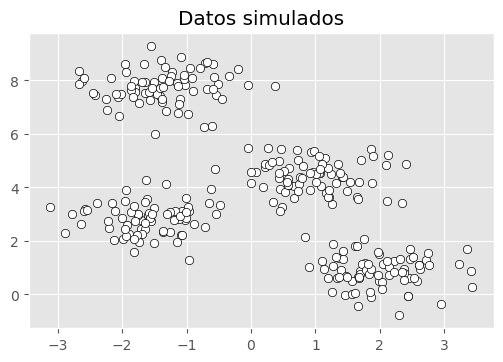

In [359]:
# Simulación de datos
# ==============================================================================
X, y = make_blobs(
        n_samples    = 300, 
        n_features   = 2, 
        centers      = 4, 
        cluster_std  = 0.60, 
        shuffle      = True, 
        random_state = 0
       )

fig, ax = plt.subplots(1, 1, figsize=(6, 3.84))
ax.scatter(
    x = X[:, 0],
    y = X[:, 1], 
    c = 'white',
    marker    = 'o',
    edgecolor = 'black', 
)
ax.set_title('Datos simulados');

In [361]:
# Modelo
from sklearn.mixture import GaussianMixture
# ==============================================================================
modelo_gmm = GaussianMixture(n_components=4, covariance_type='full', random_state=123)
modelo_gmm.fit(X=X)

,n_components,4
,covariance_type,'full'
,tol,0.001
,reg_covar,1e-06
,max_iter,100
,n_init,1
,init_params,'kmeans'
,weights_init,None
,means_init,None
,precisions_init,None
,random_state,123


El objeto devuelto por GaussianMixture contiene entre otros datos: el peso de cada componente (cluster) en el modelo (weights_), su media (means_) y matriz de covarianza (covariances_).La estructura de esta última depende del tipo de matriz empleada en el ajuste del modelo (covariance_type).

In [364]:
# Media de cada componente
modelo_gmm.means_

array([[ 0.93842466,  4.41564635],
       [-1.37355181,  7.75436785],
       [ 1.98299679,  0.86735608],
       [-1.58913964,  2.82465347]])

In [366]:
# Matriz de covarianza de cada componente
modelo_gmm.covariances_

array([[[ 0.3808649 , -0.02231979],
        [-0.02231979,  0.34881473]],

       [[ 0.41216925,  0.02884065],
        [ 0.02884065,  0.37959193]],

       [[ 0.33998651, -0.02620931],
        [-0.02620931,  0.34588507]],

       [[ 0.32360185,  0.01027908],
        [ 0.01027908,  0.30862196]]])

#### Predicción y clasificación

Una vez entrenado el modelo GMMs, se puede predecir la probabilidad que tiene cada observación de pertenecer a cada una de las componentes (clusters). Para obtener la clasificación final, se asigna a la componente con mayor probabilidad.

In [369]:
# Probabilidades
# ==============================================================================
# Cada fila es una observación y cada columna la probabilidad de pertenecer a
# cada una de las componentes.
probabilidades = modelo_gmm.predict_proba(X)
probabilidades

array([[2.59296402e-02, 8.04672295e-21, 9.71688955e-01, 2.38140471e-03],
       [7.15846263e-09, 9.99999993e-01, 7.13116691e-33, 2.34837535e-15],
       [9.99999970e-01, 2.04767765e-08, 8.78022033e-12, 9.13480329e-09],
       ...,
       [9.99965893e-01, 8.75462809e-09, 4.92339895e-10, 3.40976171e-05],
       [3.01241053e-06, 9.99996988e-01, 6.44915198e-30, 1.52780115e-18],
       [4.39280339e-07, 4.05180546e-15, 1.99754828e-11, 9.99999561e-01]])

In [371]:
# Clasificación (asignación a la componente de mayor probabilidad)
# ==============================================================================
# Cada fila es una observación y cada columna la probabilidad de pertenecer a
# cada una de las componentes.
clasificacion = modelo_gmm.predict(X)
clasificacion

array([2, 1, 0, 1, 2, 2, 3, 0, 1, 1, 3, 1, 0, 1, 2, 0, 0, 2, 3, 3, 2, 2,
       0, 3, 3, 0, 2, 0, 3, 0, 1, 1, 0, 1, 1, 1, 1, 1, 3, 2, 0, 3, 0, 0,
       3, 3, 1, 3, 1, 2, 3, 2, 1, 2, 2, 3, 1, 3, 1, 2, 1, 0, 1, 3, 3, 3,
       1, 2, 1, 3, 0, 3, 1, 3, 3, 1, 3, 0, 2, 1, 2, 0, 2, 2, 1, 0, 2, 0,
       1, 1, 0, 2, 1, 3, 3, 0, 2, 2, 0, 3, 1, 2, 1, 2, 0, 2, 2, 0, 1, 0,
       3, 3, 2, 1, 2, 0, 1, 2, 2, 0, 3, 2, 3, 2, 2, 2, 2, 3, 2, 3, 1, 3,
       3, 2, 1, 3, 3, 1, 0, 1, 1, 3, 0, 3, 0, 3, 1, 0, 1, 1, 1, 0, 1, 0,
       2, 3, 1, 3, 2, 0, 1, 0, 0, 2, 0, 3, 3, 0, 2, 0, 0, 1, 2, 0, 3, 1,
       2, 2, 0, 3, 2, 0, 3, 3, 0, 0, 0, 0, 2, 1, 0, 3, 0, 0, 3, 3, 3, 0,
       3, 1, 0, 3, 2, 3, 0, 1, 3, 1, 0, 1, 0, 3, 0, 0, 1, 3, 3, 2, 2, 0,
       1, 2, 2, 3, 2, 3, 0, 1, 1, 0, 0, 1, 0, 2, 3, 0, 2, 3, 1, 3, 2, 0,
       2, 1, 1, 1, 1, 3, 3, 1, 0, 3, 2, 0, 3, 3, 3, 2, 2, 1, 0, 0, 3, 2,
       1, 3, 0, 1, 0, 2, 2, 3, 3, 0, 2, 2, 2, 0, 1, 1, 2, 2, 0, 2, 2, 2,
       1, 3, 1, 0, 2, 2, 1, 1, 1, 2, 2, 0, 1, 3])

##### Número de clusters

Dado que los modelos GMM son modelos probabilísticos, se puede recurrir a métricas como el Akaike information criterion (AIC) o Bayesian information criterion (BIC) para identificar cómo de bien se ajustan los datos observados a modelo creado.

In [591]:
print(f"Número óptimo acorde al BIC: {range(1, 21)[np.argmin(valores_bic)]}")
print(f"Número óptimo acorde al AIC: {range(1, 21)[np.argmin(valores_aic)]}")

Número óptimo acorde al BIC: 7
Número óptimo acorde al AIC: 7


Ambas métricas identifican el 4 como número óptimo de clusters (componentes).


##### Limitaciones del clustering


1. El clustering puede ser una herramienta muy útil para encontrar agrupaciones en los datos, sobre todo a medida que el volumen de los mismos aumenta. Sin embargo, es importante recordar sus limitaciones o problemas que pueden surgir al aplicarlo. Algunas de ellas son:

Pequeñas decisiones pueden tener grandes consecuencias:a la hora de utilizar los métodos de clustering se tienen que tomar decisiones que influyen en gran medida en los resultados obtenidos. No existe una única respuesta correcta, por lo que en la práctica se prueban diferentes opciones.

-Escalado y centrado de las variables

-Qué medida de distancia/similitud emplear

-Número de clusters

-Tipo de linkage empleado en hierarchical clustering

-A que altura establecer el corte de un dendrograma


2. Validación de los clusters obtenidos: no es fácil comprobar la validez de los resultados ya que en la mayoría de escenarios se desconoce la verdadera agrupación.

3. Falta de robustez: los métodos de K-means-clustering e hierarchical clustering asignan obligatoriamente cada observación a un grupo. Si existe en la muestra algún outlier, a pesar de que realmente no pertenezca a ningún grupo, el algoritmo lo asignará a uno de ellos provocando una distorsión significativa del cluster en cuestión. Algunas alternativas son k-medoids y DBSCAN.

4. La naturaleza del algoritmo de hierarchical clustering conlleva que, si se realiza una mala división en los pasos iniciales, no se pueda corregir en los pasos siguientes.

#### Ejemplo 2

En este conjunto de datos, la agrupación jerárquica se utiliza para clasificar los 25 países europeos según su consumo de proteínas.

The dataset is inputed and the missing data is checked to make sure there is no NA value in the dataset

In [706]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Guardar en tu computador como archivo CSV
food_data.to_csv("protein.csv", index=False)

In [708]:
# 2. Inspeccionar
print(food_data.head())
print(food_data.info())
print(food_data.describe())

          Country   RedMeat   WhiteMeat   Eggs   Milk   Fish   Cereals  \
0         Albania      10.1         1.4    0.5    8.9    0.2      42.3   
1         Austria       8.9        14.0    4.3   19.9    2.1      28.0   
2         Belgium      13.5         9.3    4.1   17.5    4.5      26.6   
3        Bulgaria       7.8         6.0    1.6    8.3    1.2      56.7   
4  Czechoslovakia       9.7        11.4    2.8   12.5    2.0      34.3   

    Starch   Nuts   Fr&Veg  
0      0.6    5.5      1.7  
1      3.6    1.3      4.3  
2      5.7    2.1      4.0  
3      1.1    3.7      4.2  
4      5.0    1.1      4.0  
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25 entries, 0 to 24
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Country     25 non-null     object 
 1    RedMeat    25 non-null     float64
 2    WhiteMeat  25 non-null     float64
 3    Eggs       25 non-null     float64
 4    Milk       25 non-null    

In [710]:
# 3. Eliminar columnas irrelevantes (ej: 'Country' que es categórica)
X = food_data.drop(columns=['Country'])

In [712]:
# 4. Escalar los datos (muy importante para clustering)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [714]:
# 5. (Opcional) Reducir dimensiones con PCA para visualizar en 2D
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

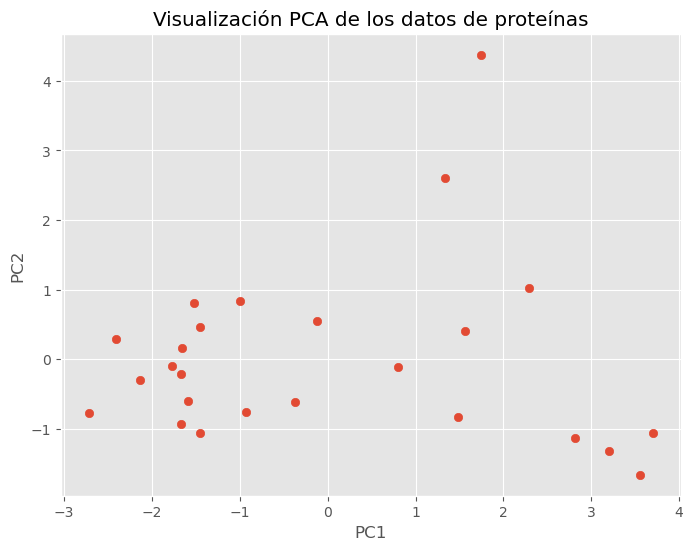

In [716]:
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1])
plt.title("Visualización PCA de los datos de proteínas")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

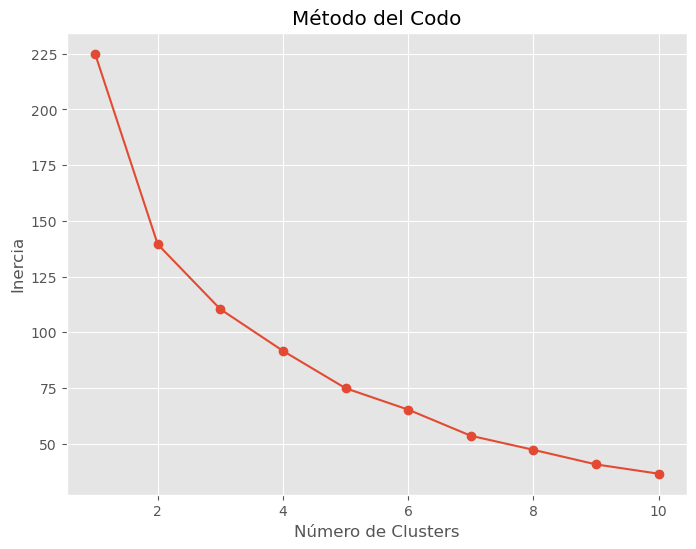

In [718]:
# 6. Determinar número óptimo de clusters con el método del codo
inertia = []
K_range = range(1, 11)
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8,6))
plt.plot(K_range, inertia, marker='o')
plt.title("Método del Codo")
plt.xlabel("Número de Clusters")
plt.ylabel("Inercia")
plt.show()


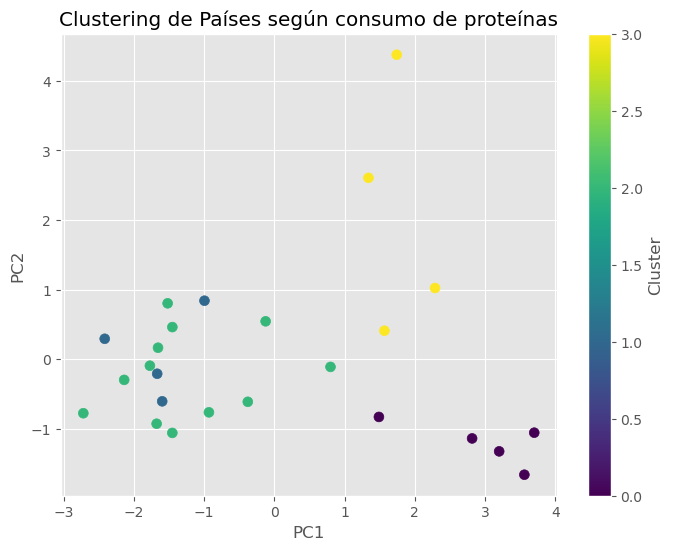

           Country  Cluster
0          Albania        0
17         Romania        0
10         Hungary        0
24      Yugoslavia        0
3         Bulgaria        0
14          Norway        1
5          Denmark        1
7          Finland        1
19          Sweden        1
22            USSR        2
21              UK        2
20     Switzerland        2
1          Austria        2
15          Poland        2
4   Czechoslovakia        2
23       W Germany        2
11         Ireland        2
2          Belgium        2
8           France        2
6        E Germany        2


In [720]:
# 6. Aplicar K-Means con el número de clusters elegido (ejemplo: 4)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 7. Agregar los clusters al dataframe original
food_data['Cluster'] = clusters

# 8. Visualización en PCA
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="viridis", s=50)
plt.title("Clustering de Países según consumo de proteínas")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(label="Cluster")
plt.show()

# 9. Ver los países por cluster
print(food_data[['Country', 'Cluster']].sort_values(by='Cluster').head(20))

Qué hace este código:

- Escala los datos para que todas las proteínas tengan la misma importancia.
- Usa el método del codo para sugerir cuántos clústeres elegir.
- Aplica K-Means con 4 clústeres (puedes cambiarlo según lo que veas en el gráfico del codo).
- Visualiza los clústeres en 2D usando PCA.
- Muestra qué países quedaron en cada clúster.

El clustering jerárquico nos permite ver cómo se agrupan los países poco a poco, y lo más común es visualizarlo con un dendrograma.

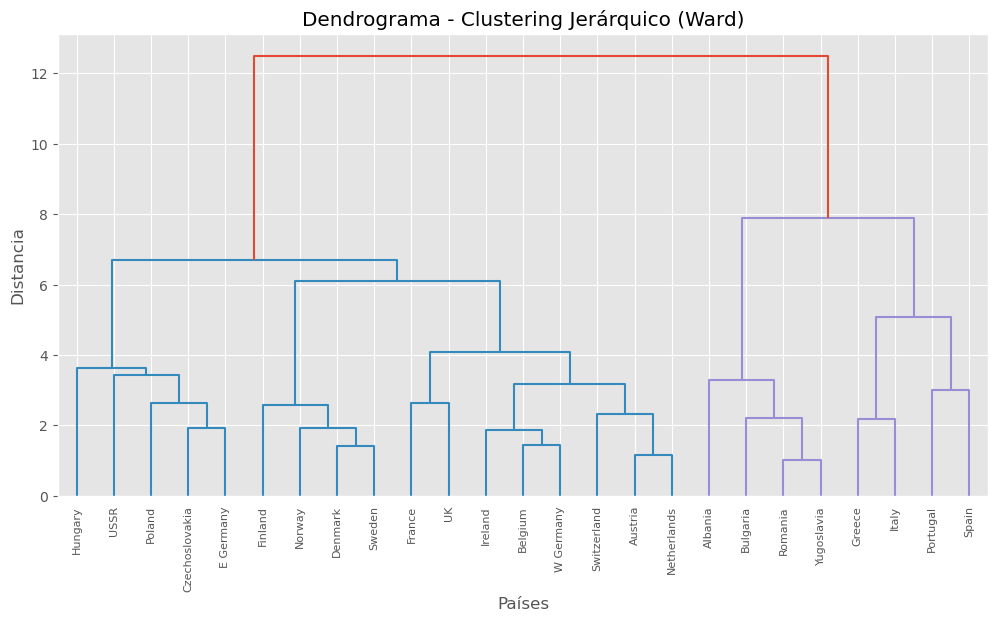

           Country  Cluster_Hier
15          Poland             1
22            USSR             1
4   Czechoslovakia             1
6        E Germany             1
10         Hungary             1
8           France             2
14          Norway             2
13     Netherlands             2
23       W Germany             2
11         Ireland             2
19          Sweden             2
20     Switzerland             2
7          Finland             2
5          Denmark             2
2          Belgium             2
1          Austria             2
21              UK             2
0          Albania             3
24      Yugoslavia             3
17         Romania             3


In [724]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster
import matplotlib.pyplot as plt

# 1. Cargar los datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Seleccionar solo las variables numéricas (quitamos 'Country')
X = food_data.drop(columns=['Country'])

# 3. Escalar los datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Clustering jerárquico (método Ward)
Z = linkage(X_scaled, method='ward')

# 5. Graficar dendrograma
plt.figure(figsize=(12,6))
dendrogram(Z, labels=food_data['Country'].values, leaf_rotation=90, leaf_font_size=8)
plt.title("Dendrograma - Clustering Jerárquico (Ward)")
plt.xlabel("Países")
plt.ylabel("Distancia")
plt.show()

# 6. Elegir número de clusters (ejemplo: 4)
clusters_hier = fcluster(Z, t=4, criterion='maxclust')

# 7. Agregar los clusters al dataframe
food_data['Cluster_Hier'] = clusters_hier

# 8. Ver resultados
print(food_data[['Country', 'Cluster_Hier']].sort_values(by='Cluster_Hier').head(20))

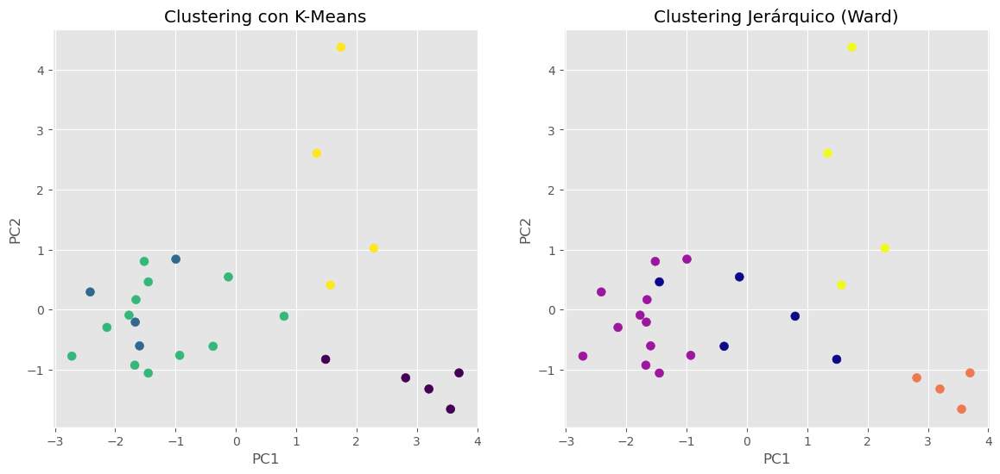

           Country  Cluster_KMeans  Cluster_Hier
0          Albania               0             3
1          Austria               2             2
2          Belgium               2             2
3         Bulgaria               0             3
4   Czechoslovakia               2             1
5          Denmark               1             2
6        E Germany               2             1
7          Finland               1             2
8           France               2             2
9           Greece               3             4
10         Hungary               0             1
11         Ireland               2             2
12           Italy               3             4
13     Netherlands               2             2
14          Norway               1             2


In [726]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster
import matplotlib.pyplot as plt

# 1. Cargar los datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Seleccionar solo las variables numéricas
X = food_data.drop(columns=['Country'])

# 3. Escalar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Reducir con PCA para visualización
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 5. K-Means clustering (4 clusters como ejemplo)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
clusters_kmeans = kmeans.fit_predict(X_scaled)
food_data["Cluster_KMeans"] = clusters_kmeans

# 6. Clustering jerárquico (Ward, 4 clusters)
Z = linkage(X_scaled, method="ward")
clusters_hier = fcluster(Z, t=4, criterion="maxclust")
food_data["Cluster_Hier"] = clusters_hier

# 7. Visualización comparativa
fig, axes = plt.subplots(1, 2, figsize=(14,6))

# --- K-Means ---
axes[0].scatter(X_pca[:,0], X_pca[:,1], c=clusters_kmeans, cmap="viridis", s=50)
axes[0].set_title("Clustering con K-Means")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

# --- Jerárquico ---
axes[1].scatter(X_pca[:,0], X_pca[:,1], c=clusters_hier, cmap="plasma", s=50)
axes[1].set_title("Clustering Jerárquico (Ward)")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.show()

# 8. Mostrar primeros resultados de asignación de clusters
print(food_data[["Country", "Cluster_KMeans", "Cluster_Hier"]].head(15))

Hagamos un análisis de similitud entre los clusters obtenidos por K-Means y Jerárquico. Para eso, lo más claro es construir una tabla de contingencia (cross-tabulation), que muestra cuántos países coinciden en cada combinación de clusters.


📊 Tabla de Contingencia (KMeans vs Jerárquico):

Cluster_Hier    1  2  3  4
Cluster_KMeans            
0               1  0  4  0
1               0  4  0  0
2               4  8  0  0
3               0  0  0  4


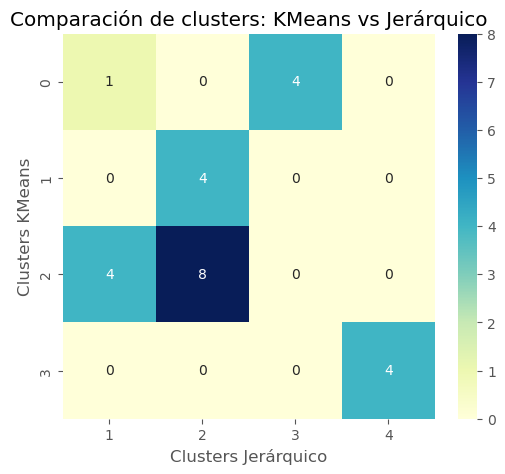

In [729]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster
import matplotlib.pyplot as plt

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos numéricos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. K-Means (4 clusters)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
food_data["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

# 4. Jerárquico (4 clusters)
Z = linkage(X_scaled, method="ward")
food_data["Cluster_Hier"] = fcluster(Z, t=4, criterion="maxclust")

# 5. Tabla de contingencia
contingencia = pd.crosstab(food_data["Cluster_KMeans"], food_data["Cluster_Hier"])
print("\n📊 Tabla de Contingencia (KMeans vs Jerárquico):\n")
print(contingencia)

# 6. Opcional: visualizar la tabla como heatmap
import seaborn as sns

plt.figure(figsize=(6,5))
sns.heatmap(contingencia, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Comparación de clusters: KMeans vs Jerárquico")
plt.xlabel("Clusters Jerárquico")
plt.ylabel("Clusters KMeans")
plt.show()

#### Explicación:

- La tabla de contingencia (pd.crosstab) muestra cómo se solapan los clusters de ambos métodos.
- Si los métodos fueran muy consistentes, verías que cada fila (KMeans) se concentra en una sola columna (Jerárquico).
- El heatmap te da una visualización intuitiva de esa coincidencia.

Para medir qué tan similares son los agrupamientos de K-Means y Jerárquico, podemos usar métricas de comparación de clústeres. Las más comunes son:

- Adjusted Rand Index (ARI): mide la similitud entre dos particiones corrigiendo por azar (0 = sin relación, 1 = idénticos).
- Normalized Mutual Information (NMI): mide cuánta información comparten las dos particiones (0 = sin relación, 1 = idénticos).
Aquí tienes el código para calcularlas:

In [733]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. K-Means (4 clusters)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
food_data["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

# 4. Jerárquico (4 clusters)
Z = linkage(X_scaled, method="ward")
food_data["Cluster_Hier"] = fcluster(Z, t=4, criterion="maxclust")

# 5. Métricas de similitud
ari = adjusted_rand_score(food_data["Cluster_KMeans"], food_data["Cluster_Hier"])
nmi = normalized_mutual_info_score(food_data["Cluster_KMeans"], food_data["Cluster_Hier"])

print("🔎 Comparación entre K-Means y Jerárquico:")
print(f"Adjusted Rand Index (ARI): {ari:.3f}")
print(f"Normalized Mutual Information (NMI): {nmi:.3f}")

🔎 Comparación entre K-Means y Jerárquico:
Adjusted Rand Index (ARI): 0.421
Normalized Mutual Information (NMI): 0.678


Interpretación:
- ARI ≈ 1: los métodos asignaron clusters casi idénticos.
- ARI ≈ 0: los clusters no tienen relación (puro azar).
- NMI ≈ 1: mucha información compartida entre métodos.
- NMI ≈ 0: asignaciones sin relación.

Ahora vamos a identificar qué países cambian de cluster entre K-Means y Jerárquico. Esto nos permite ver en qué casos los métodos discrepan.
Aquí tienes el código:

In [737]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. K-Means (4 clusters)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
food_data["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

# 4. Jerárquico (4 clusters)
Z = linkage(X_scaled, method="ward")
food_data["Cluster_Hier"] = fcluster(Z, t=4, criterion="maxclust")

# 5. Identificar países con asignaciones distintas
diferentes = food_data[food_data["Cluster_KMeans"] != food_data["Cluster_Hier"]]

print("🔎 Países que cambian de cluster entre K-Means y Jerárquico:\n")
print(diferentes[["Country", "Cluster_KMeans", "Cluster_Hier"]].sort_values(by="Country"))

🔎 Países que cambian de cluster entre K-Means y Jerárquico:

           Country  Cluster_KMeans  Cluster_Hier
0          Albania               0             3
3         Bulgaria               0             3
4   Czechoslovakia               2             1
5          Denmark               1             2
6        E Germany               2             1
7          Finland               1             2
9           Greece               3             4
10         Hungary               0             1
12           Italy               3             4
14          Norway               1             2
15          Poland               2             1
16        Portugal               3             4
17         Romania               0             3
18           Spain               3             4
19          Sweden               1             2
22            USSR               2             1
24      Yugoslavia               0             3


Una tabla con los países que no coinciden en los dos métodos.
Para cada país, se muestra a qué cluster K-Means pertenece y a qué cluster Jerárquico fue asignado.

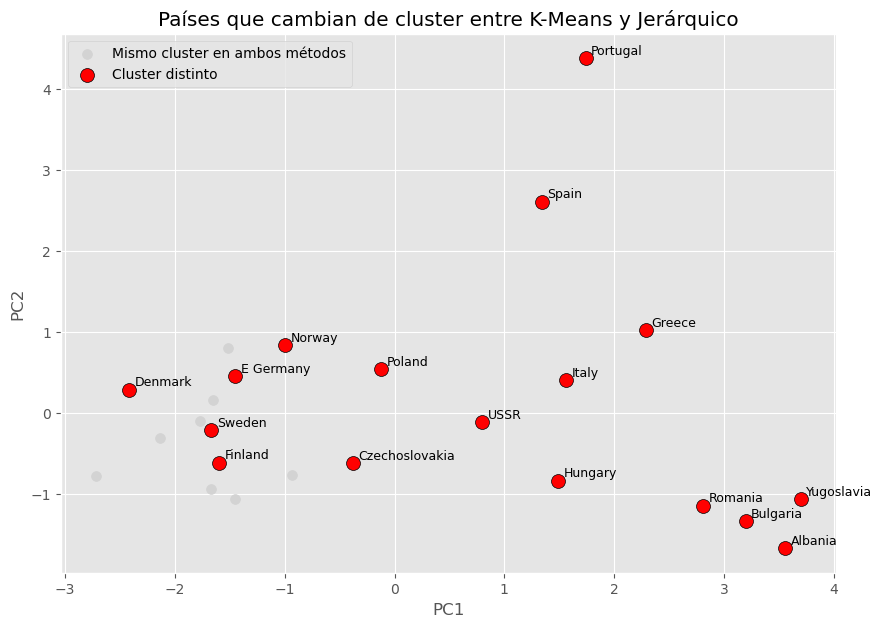

In [740]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster
import matplotlib.pyplot as plt

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Reducir a 2D con PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 4. K-Means (4 clusters)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
food_data["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

# 5. Jerárquico (4 clusters)
Z = linkage(X_scaled, method="ward")
food_data["Cluster_Hier"] = fcluster(Z, t=4, criterion="maxclust")

# 6. Detectar países que cambian de cluster
food_data["Diferente"] = food_data["Cluster_KMeans"] != food_data["Cluster_Hier"]

# 7. Visualización en PCA
plt.figure(figsize=(10,7))

# Países iguales en ambos métodos → color gris
plt.scatter(X_pca[~food_data["Diferente"],0], 
            X_pca[~food_data["Diferente"],1], 
            c="lightgray", s=50, label="Mismo cluster en ambos métodos")

# Países diferentes → color rojo
plt.scatter(X_pca[food_data["Diferente"],0], 
            X_pca[food_data["Diferente"],1], 
            c="red", s=100, edgecolors="black", label="Cluster distinto")

# Etiquetas para los países que cambian
for i, row in food_data[food_data["Diferente"]].iterrows():
    plt.text(X_pca[i,0]+0.05, X_pca[i,1]+0.05, row["Country"], fontsize=9)

plt.title("Países que cambian de cluster entre K-Means y Jerárquico")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend()
plt.show()

Explicación:
-Los puntos grises son países que quedaron en el mismo cluster en ambos métodos.
- Los puntos rojos son países que cambiaron de cluster, y están etiquetados con su nombre.
- Esto te permite ver gráficamente dónde ocurren las discrepancias en el espacio de datos.

Hagamos ahora un reporte en tabla resumida para ver de manera clara cómo se mueven los países que cambian de cluster entre K-Means y Jerárquico.
La idea es:
- Filtrar solo los países que cambian.
- Hacer una tabla cruzada entre Cluster_KMeans y Cluster_Hier, pero únicamente con los países que difieren.
Aquí tienes el código:

In [744]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from scipy.cluster.hierarchy import linkage, fcluster

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. K-Means (4 clusters)
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
food_data["Cluster_KMeans"] = kmeans.fit_predict(X_scaled)

# 4. Jerárquico (4 clusters)
Z = linkage(X_scaled, method="ward")
food_data["Cluster_Hier"] = fcluster(Z, t=4, criterion="maxclust")

# 5. Filtrar países que cambian de cluster
diferentes = food_data[food_data["Cluster_KMeans"] != food_data["Cluster_Hier"]]

# 6. Tabla resumen de cómo se mueven
movimientos = pd.crosstab(diferentes["Cluster_KMeans"], diferentes["Cluster_Hier"])

print("🔎 Tabla de movimientos de países que cambian de cluster:\n")
print(movimientos)

# 7. Mostrar detalle de los países
print("\n📌 Lista de países que cambian de cluster:\n")
print(diferentes[["Country", "Cluster_KMeans", "Cluster_Hier"]].sort_values("Cluster_KMeans"))


🔎 Tabla de movimientos de países que cambian de cluster:

Cluster_Hier    1  2  3  4
Cluster_KMeans            
0               1  0  4  0
1               0  4  0  0
2               4  0  0  0
3               0  0  0  4

📌 Lista de países que cambian de cluster:

           Country  Cluster_KMeans  Cluster_Hier
0          Albania               0             3
17         Romania               0             3
10         Hungary               0             1
24      Yugoslavia               0             3
3         Bulgaria               0             3
7          Finland               1             2
14          Norway               1             2
19          Sweden               1             2
5          Denmark               1             2
6        E Germany               2             1
4   Czechoslovakia               2             1
22            USSR               2             1
15          Poland               2             1
9           Greece               3             4
1

k=2, Silhouette=0.327
k=3, Silhouette=0.335
k=4, Silhouette=0.254
k=5, Silhouette=0.264
k=6, Silhouette=0.237
k=7, Silhouette=0.247
k=8, Silhouette=0.231
k=9, Silhouette=0.239
k=10, Silhouette=0.201


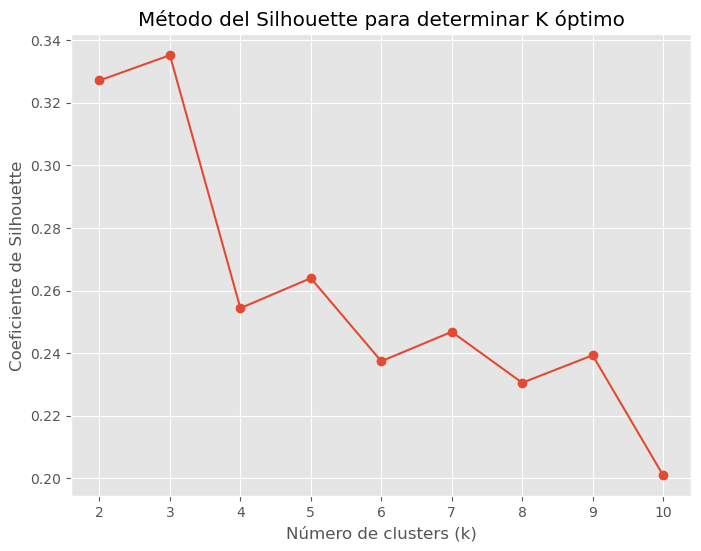

In [746]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos (quitamos columna no numérica)
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Calcular Silhouette para varios K
silhouette_scores = []
K_range = range(2, 11)  # el silhouette no se calcula para k=1

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)
    print(f"k={k}, Silhouette={score:.3f}")

# 4. Graficar resultados
plt.figure(figsize=(8,6))
plt.plot(K_range, silhouette_scores, marker="o")
plt.title("Método del Silhouette para determinar K óptimo")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de Silhouette")
plt.grid(True)
plt.show()

el mayor k, k=3, Silhouette=0.335. El optimo son tres cluster

#### Un scatterplot PCA 2D con los países coloreados según su cluster óptimo.
El mejor número de clusters elegido automáticamente con silhouette. Una tabla con los países y el cluster asignado.

✅ Mejor número de clusters según silhouette: k=3, score=0.335


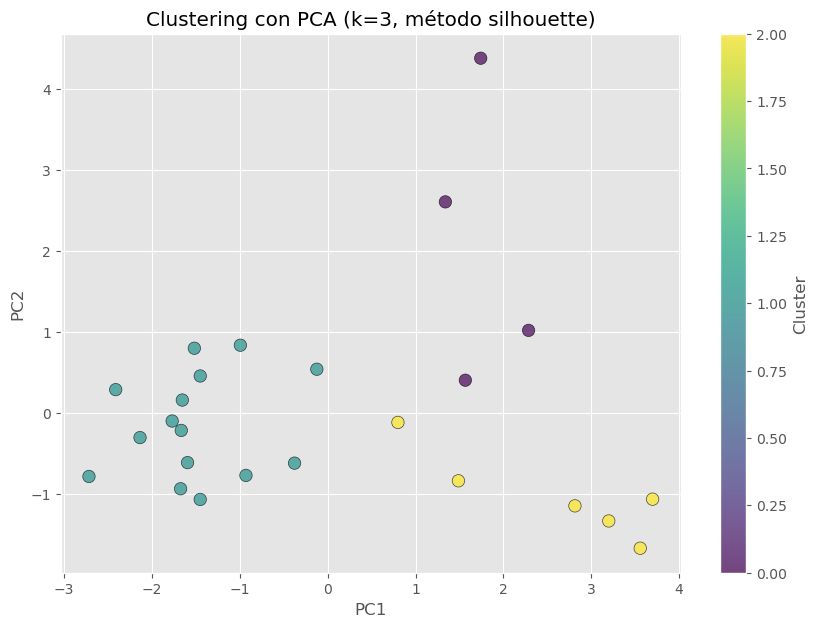

           Country  Cluster
12           Italy        0
16        Portugal        0
18           Spain        0
9           Greece        0
4   Czechoslovakia        1
5          Denmark        1
6        E Germany        1
7          Finland        1
8           France        1
2          Belgium        1
21              UK        1
11         Ireland        1
23       W Germany        1
13     Netherlands        1
14          Norway        1
15          Poland        1
1          Austria        1
20     Switzerland        1
19          Sweden        1
22            USSR        2


In [753]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Probar varios k y elegir el mejor según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar KMeans con el mejor k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)
food_data["Cluster"] = clusters

# 5. Reducir con PCA a 2D para visualizar
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# 6. Graficar clusters en PCA
plt.figure(figsize=(10,7))
scatter = plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="viridis", s=80, alpha=0.7, edgecolors="k")
plt.title(f"Clustering con PCA (k={best_k}, método silhouette)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.colorbar(scatter, label="Cluster")
plt.show()

# 7. Mostrar países asignados a clusters
print(food_data[["Country", "Cluster"]].sort_values("Cluster").head(20))

Ahora que ya tenemos los clusters óptimos con el método Silhouette, podemos hacer un análisis interpretativo viendo el promedio de consumo de proteínas por cluster.

Esto nos ayuda a darle “significado” a cada grupo (ejemplo: países con alto consumo de carne, países con dieta basada en pescado, etc.).

In [756]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Determinar el mejor número de clusters según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar clustering final con el mejor k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Tabla con el promedio de consumo de proteínas por cluster
cluster_means = food_data.groupby("Cluster").mean(numeric_only=True)

print("\n📊 Promedio de consumo de proteínas por cluster:\n")
print(cluster_means)

# 6. Opcional: exportar tabla a CSV
cluster_means.to_csv("cluster_means_protein.csv")

✅ Mejor número de clusters según silhouette: k=3, score=0.335

📊 Promedio de consumo de proteínas por cluster:

           RedMeat   WhiteMeat      Eggs       Milk      Fish    Cereals  \
Cluster                                                                    
0         8.125000    3.800000  2.475000  11.200000  7.625000  33.675000   
1        11.340000    9.766667  3.580000  21.260000  4.686667  25.553333   
2         7.183333    5.950000  1.633333  10.683333  1.050000  48.033333   

           Starch      Nuts    Fr&Veg  
Cluster                                
0        3.975000  5.675000  7.075000  
1        4.853333  1.673333  3.740000  
2        3.033333  4.833333  3.166667  


- Cluster 0 → países con alto consumo de pescado.
- Cluster 1 → países con alto consumo de carne roja y leche.
- Cluster 2 → países con dieta más balanceada.

✅ Mejor número de clusters según silhouette: k=3, score=0.335

📊 Promedio de los clusters en componentes principales (PCA):

              PC1       PC2
Cluster                    
0        1.732995  2.103118
1       -1.499035 -0.151557
2        2.592258 -1.023186


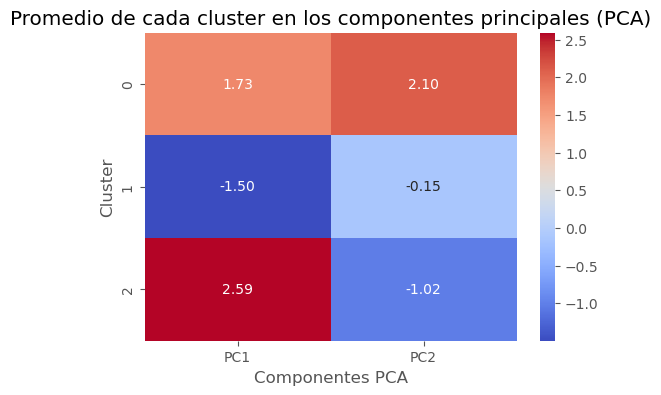

In [759]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos (quitamos columna no numérica)
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Determinar el mejor número de clusters según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar clustering final
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Reducir dimensiones con PCA
pca = PCA(n_components=2)  # para análisis visual
X_pca = pca.fit_transform(X_scaled)

food_data["PC1"] = X_pca[:,0]
food_data["PC2"] = X_pca[:,1]

# 6. Calcular promedio de cada cluster en los componentes PCA
cluster_means_pca = food_data.groupby("Cluster")[["PC1", "PC2"]].mean()
print("\n📊 Promedio de los clusters en componentes principales (PCA):\n")
print(cluster_means_pca)

# 7. Visualización con heatmap
plt.figure(figsize=(6,4))
sns.heatmap(cluster_means_pca, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Promedio de cada cluster en los componentes principales (PCA)")
plt.xlabel("Componentes PCA")
plt.ylabel("Cluster")
plt.show()

El biplot PCA es la mejor forma de ver:
- Cómo se distribuyen los países en los componentes principales.
- Cómo contribuye cada tipo de proteína (variables originales) a esos componentes.
- Aquí tienes el código completo que incluye el biplot con clusters y cargas de las variables:

✅ Mejor número de clusters según silhouette: k=3, score=0.335


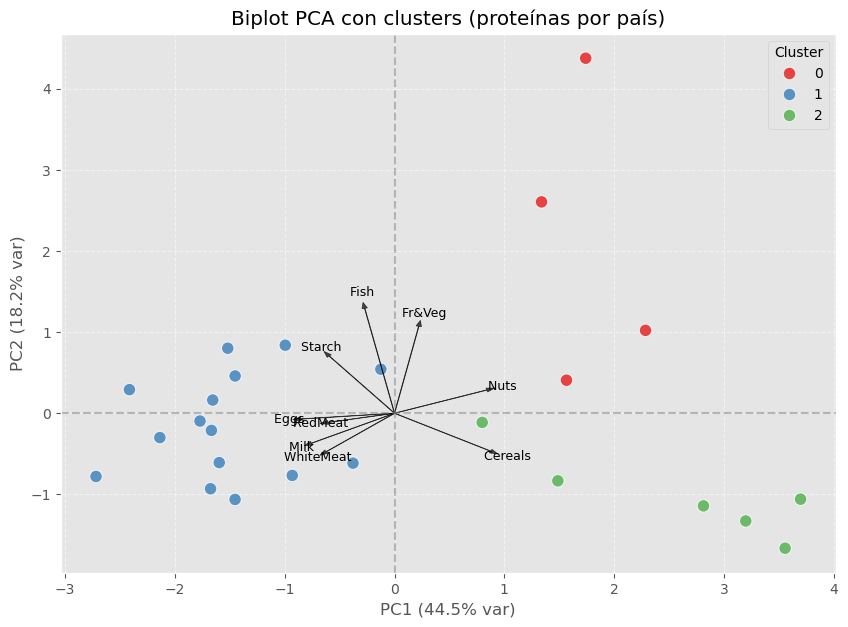

In [762]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos (quitamos columna no numérica)
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Determinar el mejor número de clusters según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar clustering final
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. PCA con 2 componentes
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

food_data["PC1"] = X_pca[:,0]
food_data["PC2"] = X_pca[:,1]

# 6. Biplot con clusters + cargas de variables
plt.figure(figsize=(10,7))

# Graficar países coloreados por cluster
sns.scatterplot(
    x="PC1", y="PC2",
    hue="Cluster", data=food_data,
    palette="Set1", s=80, alpha=0.8
)

# Dibujar vectores de las variables originales
loadings = pca.components_.T * 2  # escalamos vectores para visualización
for i, var in enumerate(X.columns):
    plt.arrow(0, 0, loadings[i,0], loadings[i,1],
              color="black", alpha=0.7, width=0.005, head_width=0.05)
    plt.text(loadings[i,0]*1.15, loadings[i,1]*1.15,
             var, color="black", ha="center", va="center", fontsize=9)

plt.title("Biplot PCA con clusters (proteínas por país)")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]*100:.1f}% var)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]*100:.1f}% var)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.axhline(0, color="gray", linestyle="--", alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", alpha=0.5)
plt.show()

Puntos: cada país, coloreado según su cluster.
- Ejes PC1 y PC2: las principales direcciones de variación en el consumo de proteínas.
- Flechas (vectores): representan los alimentos (carne roja, pescado, leche, etc.) y hacia dónde empujan la varianza.
- Si un cluster está hacia la dirección de la flecha de “Fish”, significa que ese grupo de países consume mucho pescado.
- Si está hacia “RedMeat”, son países con dieta basada en carne roja.

✅ Mejor número de clusters según silhouette: k=3, score=0.335


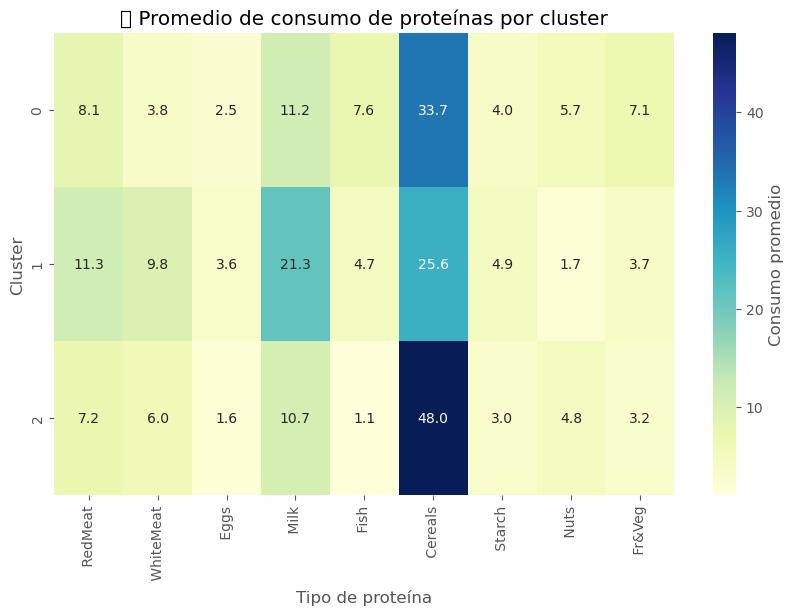

In [765]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Cargar datos
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# 2. Preparar datos
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Determinar el mejor número de clusters según silhouette
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"✅ Mejor número de clusters según silhouette: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# 4. Ejecutar clustering final con el mejor k
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# 5. Tabla con promedio de consumo por cluster
cluster_means = food_data.groupby("Cluster").mean(numeric_only=True)

# 6. Heatmap de perfiles de consumo
plt.figure(figsize=(10,6))
sns.heatmap(cluster_means, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Consumo promedio'})
plt.title("📊 Promedio de consumo de proteínas por cluster")
plt.xlabel("Tipo de proteína")
plt.ylabel("Cluster")
plt.show()

Un heatmap donde cada fila es un cluster y cada columna un tipo de proteína.
- Los colores indican el nivel relativo de consumo promedio (más oscuro = mayor consumo).
- Te permite ver patrones claros, por ejemplo:
- Un cluster puede tener alto consumo de pescado y bajo de carne roja.
- Otro cluster puede tener alto consumo de leche y huevos.

El radar chart (gráfico de araña) es perfecto para ver los perfiles nutricionales de cada cluster de manera comparativa, como una “huella” de consumo.

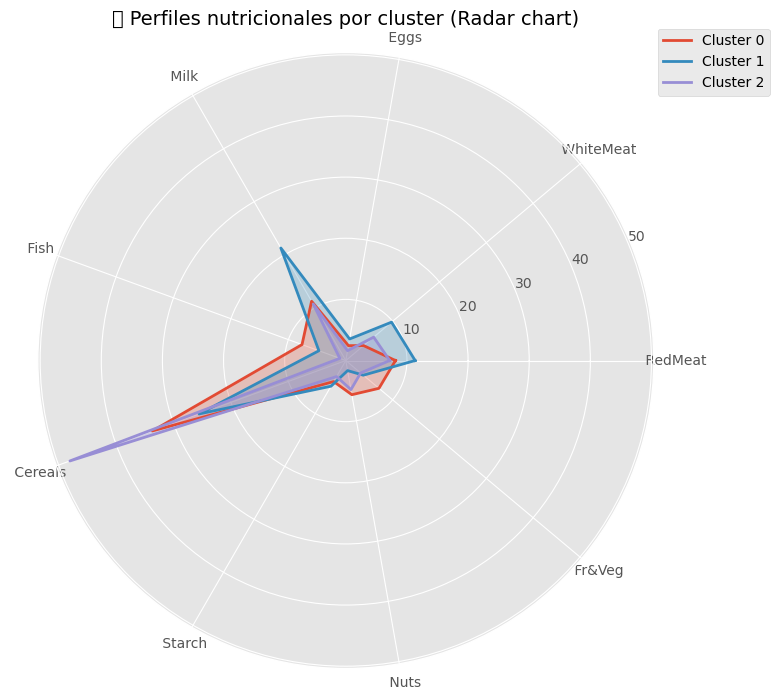

In [769]:
import matplotlib.pyplot as plt
import numpy as np

# Usamos la tabla de medias por cluster que ya calculamos
cluster_means = food_data.groupby("Cluster").mean(numeric_only=True)

# Variables (tipos de proteínas)
categories = list(cluster_means.columns)
N = len(categories)

# Ángulos para el gráfico circular
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]  # cerrar el círculo

# Crear gráfico de araña
plt.figure(figsize=(8,8))

for i, row in cluster_means.iterrows():
    values = row.tolist()
    values += values[:1]  # cerrar el círculo
    plt.polar(angles, values, label=f"Cluster {i}", linewidth=2)
    plt.fill(angles, values, alpha=0.25)

# Etiquetas de cada eje
plt.xticks(angles[:-1], categories, fontsize=10)
plt.title("🌍 Perfiles nutricionales por cluster (Radar chart)", size=14, pad=20)
plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1.05))
plt.show()

- Cada línea/área representa un cluster.
- El tamaño de cada eje muestra el consumo promedio en ese tipo de proteína.
- Los clusters se comparan fácilmente: por ejemplo, uno puede estar “inflado” hacia Fish, otro hacia RedMeat, otro hacia Milk, etc.

Primeras filas del dataset:
          Country   RedMeat   WhiteMeat   Eggs   Milk   Fish   Cereals  \
0         Albania      10.1         1.4    0.5    8.9    0.2      42.3   
1         Austria       8.9        14.0    4.3   19.9    2.1      28.0   
2         Belgium      13.5         9.3    4.1   17.5    4.5      26.6   
3        Bulgaria       7.8         6.0    1.6    8.3    1.2      56.7   
4  Czechoslovakia       9.7        11.4    2.8   12.5    2.0      34.3   

    Starch   Nuts   Fr&Veg  
0      0.6    5.5      1.7  
1      3.6    1.3      4.3  
2      5.7    2.1      4.0  
3      1.1    3.7      4.2  
4      5.0    1.1      4.0  

Dimensiones: (25, 10)

Varianza explicada por los 2 primeros componentes: [0.44515973 0.18166661]

✅ Mejor número de clusters: k=3, score=0.335


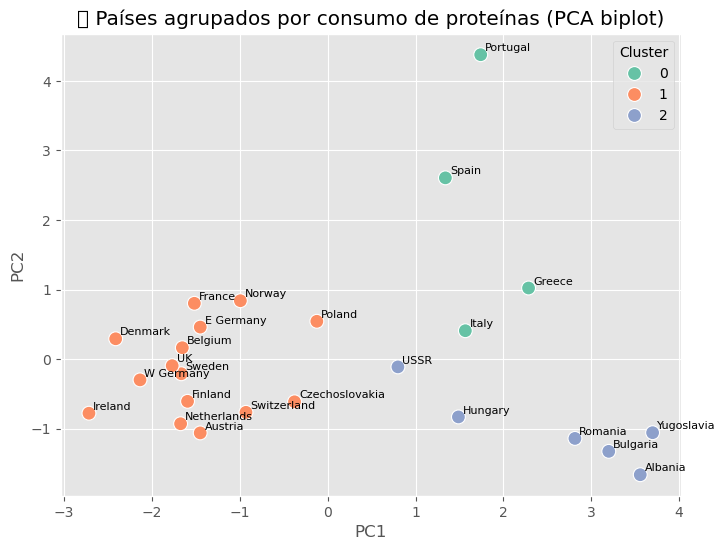

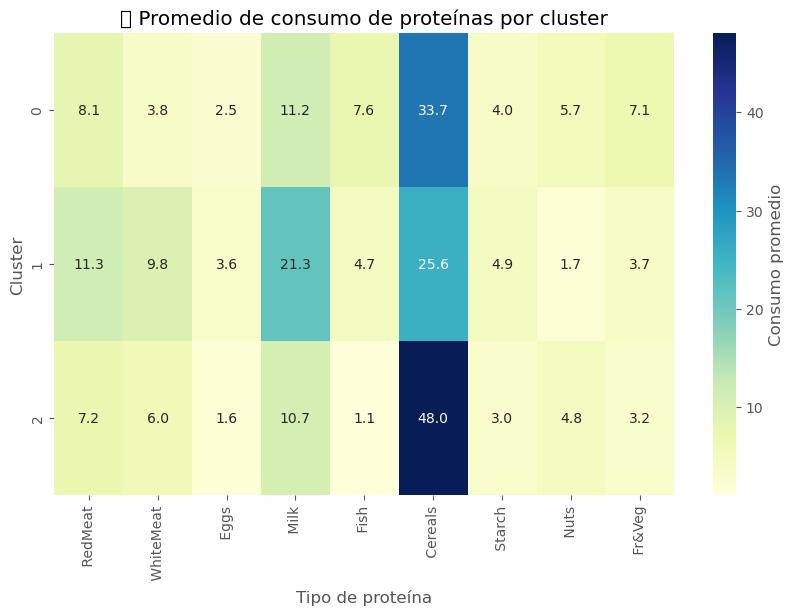

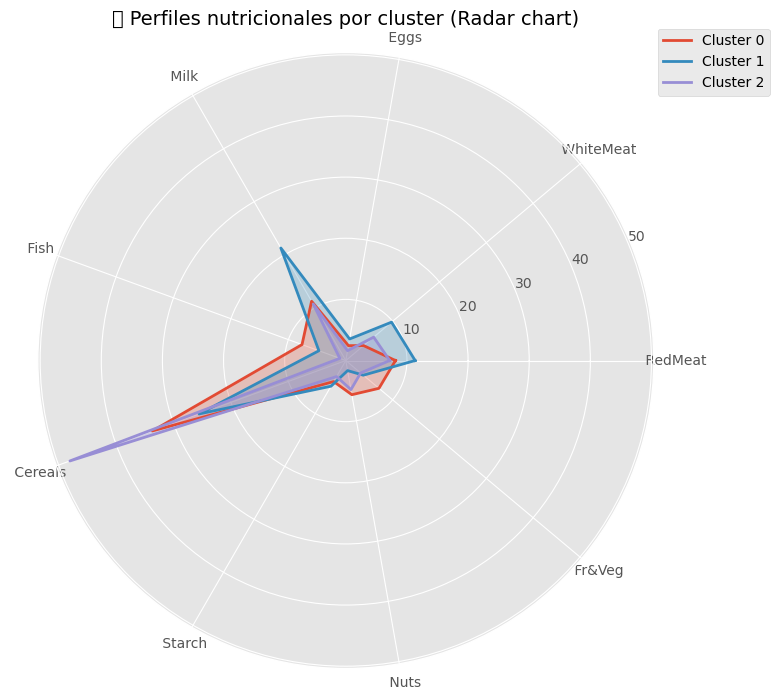

In [772]:
# ============================================
# 1. Importar librerías
# ============================================
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================
# 2. Cargar y explorar datos
# ============================================
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

print("Primeras filas del dataset:")
print(food_data.head())
print("\nDimensiones:", food_data.shape)

# ============================================
# 3. Normalizar datos
# ============================================
X = food_data.drop(columns=["Country"])
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ============================================
# 4. PCA para reducción de dimensión
# ============================================
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

print("\nVarianza explicada por los 2 primeros componentes:", pca.explained_variance_ratio_)

# ============================================
# 5. Determinar número óptimo de clusters con silhouette
# ============================================
silhouette_scores = {}
K_range = range(2, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)
    silhouette_scores[k] = silhouette_score(X_scaled, labels)

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\n✅ Mejor número de clusters: k={best_k}, score={silhouette_scores[best_k]:.3f}")

# ============================================
# 6. Clustering final
# ============================================
kmeans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
food_data["Cluster"] = kmeans.fit_predict(X_scaled)

# ============================================
# 7. Visualización: PCA Biplot con clusters
# ============================================
plt.figure(figsize=(8,6))
sns.scatterplot(x=X_pca[:,0], y=X_pca[:,1], hue=food_data["Cluster"], palette="Set2", s=100)
for i, country in enumerate(food_data["Country"]):
    plt.text(X_pca[i,0]+0.05, X_pca[i,1]+0.05, country, fontsize=8)
plt.title("🌍 Países agrupados por consumo de proteínas (PCA biplot)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.legend(title="Cluster")
plt.show()

# ============================================
# 8. Heatmap de promedios por cluster
# ============================================
cluster_means = food_data.groupby("Cluster").mean(numeric_only=True)

plt.figure(figsize=(10,6))
sns.heatmap(cluster_means, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Consumo promedio'})
plt.title("📊 Promedio de consumo de proteínas por cluster")
plt.xlabel("Tipo de proteína")
plt.ylabel("Cluster")
plt.show()

# ============================================
# 9. Radar chart de perfiles nutricionales
# ============================================
categories = list(cluster_means.columns)
N = len(categories)
angles = np.linspace(0, 2*np.pi, N, endpoint=False).tolist()
angles += angles[:1]

plt.figure(figsize=(8,8))

for i, row in cluster_means.iterrows():
    values = row.tolist()
    values += values[:1]
    plt.polar(angles, values, label=f"Cluster {i}", linewidth=2)
    plt.fill(angles, values, alpha=0.25)

plt.xticks(angles[:-1], categories, fontsize=10)
plt.title("🍽️ Perfiles nutricionales por cluster (Radar chart)", size=14, pad=20)
plt.legend(loc="upper right", bbox_to_anchor=(1.2, 1.05))
plt.show()

#### K-Medoids

- Estandariza las variables de consumo de proteínas.
- Reduce a 2 componentes principales (para visualización).
- Ajusta un modelo K-Medoids con k=4 (puedes cambiar el número).
- Grafica los clusters y los medoides en rojo.
- Te da un DataFrame con cada país asignado a un cluster.

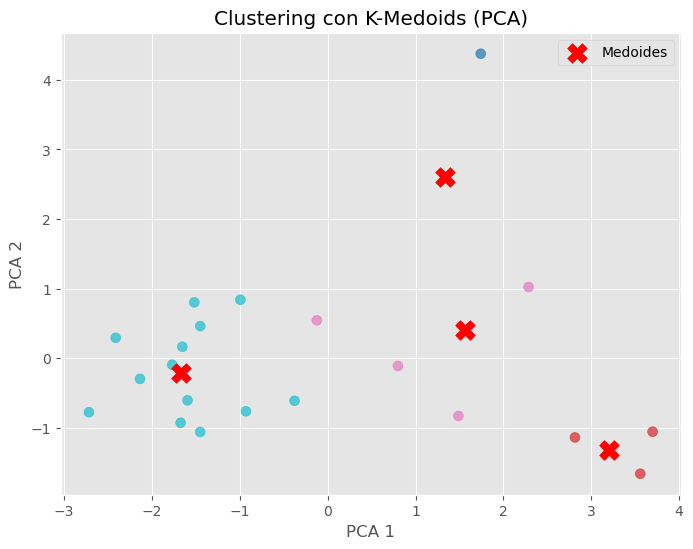

          Country  Cluster
0         Albania        1
1         Austria        3
2         Belgium        3
3        Bulgaria        1
4  Czechoslovakia        3


In [775]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn_extra.cluster import KMedoids

# ===============================
# 1. Cargar y preparar datos
# ===============================
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Estandarizar variables (sin la columna "Country")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(food_data.iloc[:, 1:])

# Reducir a 2 componentes principales
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# ===============================
# 2. Ajustar modelo K-Medoids
# ===============================
k = 4  # número de clusters (puedes cambiarlo según Silhouette o GAP)
kmedoids = KMedoids(n_clusters=k, random_state=42, method="pam", metric="euclidean")
clusters = kmedoids.fit_predict(X_pca)

# ===============================
# 3. Visualización
# ===============================
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="tab10", s=50, alpha=0.7)
plt.scatter(kmedoids.cluster_centers_[:,0], kmedoids.cluster_centers_[:,1], 
            c="red", marker="X", s=200, label="Medoides")
plt.title("Clustering con K-Medoids (PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.show()

# ===============================
# 4. Asignación de países a clusters
# ===============================
food_data["Cluster"] = clusters
print(food_data[["Country", "Cluster"]].head())

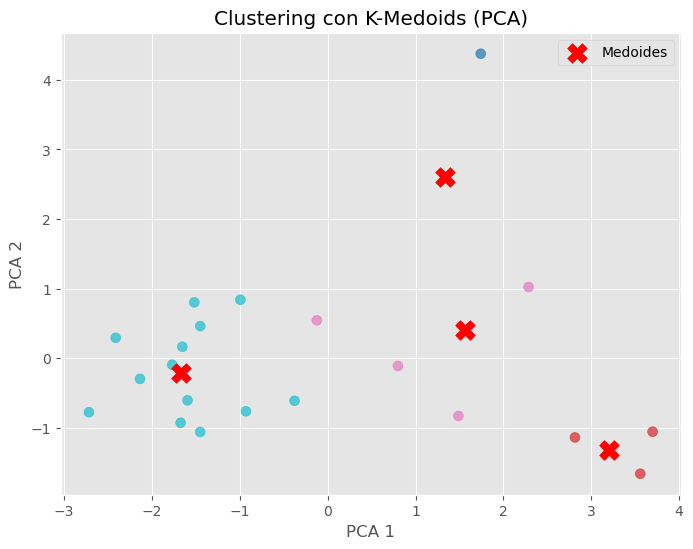

          Country  Cluster
0         Albania        1
1         Austria        3
2         Belgium        3
3        Bulgaria        1
4  Czechoslovakia        3


In [777]:
!pip install scikit-learn-extra -q
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn_extra.cluster import KMedoids

# ===============================
# 1. Cargar y preparar datos
# ===============================
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Estandarizar variables (sin la columna "Country")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(food_data.iloc[:, 1:])

# Reducir a 2 componentes principales
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# ===============================
# 2. Ajustar modelo K-Medoids
# ===============================
k = 4  # número de clusters (puedes cambiarlo según Silhouette o GAP)
kmedoids = KMedoids(n_clusters=k, random_state=42, method="pam", metric="euclidean")
clusters = kmedoids.fit_predict(X_pca)

# ===============================
# 3. Visualización
# ===============================
plt.figure(figsize=(8,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=clusters, cmap="tab10", s=50, alpha=0.7)
plt.scatter(kmedoids.cluster_centers_[:,0], kmedoids.cluster_centers_[:,1], 
            c="red", marker="X", s=200, label="Medoides")
plt.title("Clustering con K-Medoids (PCA)")
plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.legend()
plt.show()

# ===============================
# 4. Asignación de países a clusters
# ===============================
food_data["Cluster"] = clusters
print(food_data[["Country", "Cluster"]].head())

#### A continuacion
- Prepara y estandariza los datos.
- Reduce dimensión con PCA (2 componentes).
- Aplica K-Medoids variando k de 2 a 9.
- Calcula el Coeficiente Silhouette y grafica la curva.
- Escoge el mejor k automáticamente.
- Muestra la visualización en PCA con los clusters y los medoides.

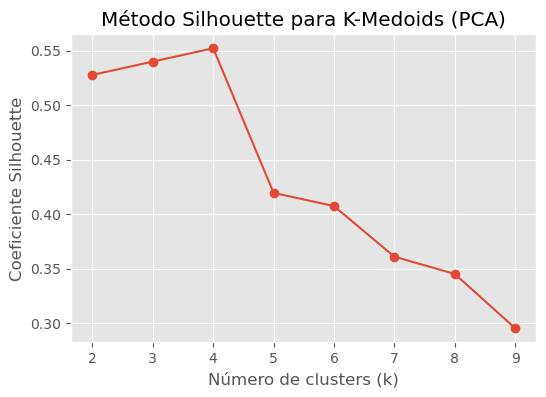

✅ El número óptimo de clusters según Silhouette es: 4


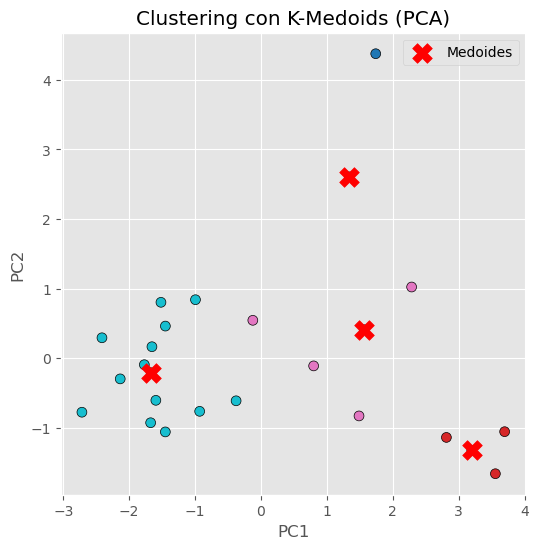

In [779]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn_extra.cluster import KMedoids
import matplotlib.pyplot as plt

# ==============================
# 1. Cargar datos
# ==============================
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Guardar nombres de países
countries = food_data.iloc[:, 0]

# Solo variables numéricas
X = food_data.iloc[:, 1:]

# ==============================
# 2. Estandarización + PCA
# ==============================
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

# ==============================
# 3. Validación con Silhouette
# ==============================
sil_scores = []
K_range = range(2, 10)

for k in K_range:
    kmedoids = KMedoids(n_clusters=k, random_state=42, method="pam")
    labels = kmedoids.fit_predict(X_pca)
    sil = silhouette_score(X_pca, labels)
    sil_scores.append(sil)

# Gráfico del método silhouette
plt.figure(figsize=(6,4))
plt.plot(K_range, sil_scores, marker='o')
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente Silhouette")
plt.title("Método Silhouette para K-Medoids (PCA)")
plt.show()

# ==============================
# 4. Mejor número de clusters
# ==============================
best_k = K_range[np.argmax(sil_scores)]
print(f"✅ El número óptimo de clusters según Silhouette es: {best_k}")

# ==============================
# 5. Ajustar modelo final
# ==============================
kmedoids_final = KMedoids(n_clusters=best_k, random_state=42, method="pam")
labels_final = kmedoids_final.fit_predict(X_pca)

food_data["Cluster"] = labels_final

# Visualización en PCA
plt.figure(figsize=(6,6))
plt.scatter(X_pca[:,0], X_pca[:,1], c=labels_final, cmap="tab10", s=50, edgecolor="k")
plt.scatter(kmedoids_final.cluster_centers_[:,0], 
            kmedoids_final.cluster_centers_[:,1],
            c="red", marker="X", s=200, label="Medoides")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Clustering con K-Medoids (PCA)")
plt.legend()
plt.show()


📊 Promedio de consumo por cluster:
           RedMeat   WhiteMeat      Eggs   Milk       Fish   Cereals  \
Cluster                                                                
0         6.650000    3.550000  2.100000   6.75  10.600000    28.100   
1         7.125000    4.675000  1.200000   9.45   0.750000    51.125   
2         8.140000    7.060000  2.680000  15.38   3.120000    39.660   
3        11.657143    9.735714  3.642857  21.40   4.807143    24.800   

           Starch   Nuts    Fr&Veg  
Cluster                             
0        5.800000   5.30  7.550000  
1        1.950000   5.05  2.975000  
2        4.120000   4.58  5.380000  
3        4.778571   1.65  3.535714  


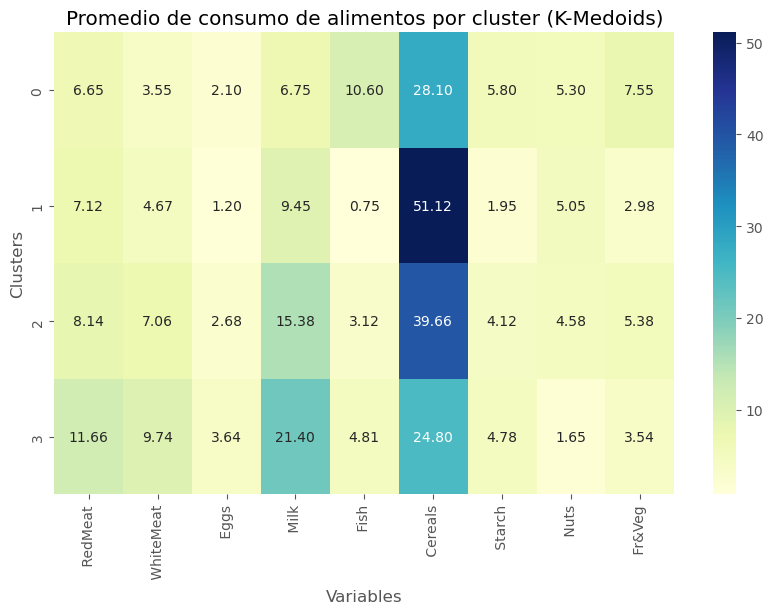

In [782]:
# ==============================
# 6. Tabla resumen por cluster
# ==============================
cluster_summary = food_data.groupby("Cluster").mean(numeric_only=True)

print("\n📊 Promedio de consumo por cluster:")
print(cluster_summary)

# ==============================
# 7. Visualización en heatmap
# ==============================
import seaborn as sns

plt.figure(figsize=(10,6))
sns.heatmap(cluster_summary, annot=True, fmt=".2f", cmap="YlGnBu")
plt.title("Promedio de consumo de alimentos por cluster (K-Medoids)")
plt.xlabel("Variables")
plt.ylabel("Clusters")
plt.show()

En K-means, el representante del cluster es el centroide (media aritmética), lo que solo tiene sentido con distancia euclídea.
En K-medoids, el representante del cluster es un medoide, es decir, un punto real del dataset que minimiza la suma de distancias a los demás puntos del cluster.
Como el medoide es un punto real y no un promedio, el algoritmo puede trabajar con cualquier métrica de distancia siempre que esté bien definida.

Ejemplos de distancias que puedes usar con K-medoids
- Euclídea (por defecto, como K-means)
- Manhattan (L1)
- Coseno
- Mahalanobis
- Hamming (para variables categóricas codificadas en binario)

Guía práctica
1. Datos numéricos en un espacio continuo
- Distancia Euclídea → estándar, funciona bien si todas las variables están en la misma escala.
- Distancia Manhattan (L1) → más robusta a outliers que la euclídea.
- Distancia Mahalanobis → recomendable si las variables están correlacionadas o tienen escalas muy diferentes (considera la covarianza).
- 👉 Consejo: si las variables están en distintas escalas, normaliza antes (z-score o min-max).

2. Datos de alta dimensión (ej. texto, imágenes, embeddings)
- Distancia Coseno → muy útil si importa la dirección del vector más que su magnitud (ej. NLP, TF-IDF, word embeddings).
- Distancia Correlación → mide similitud de patrones más que magnitudes.

3. Datos categóricos o mixtos
- Distancia Hamming → adecuada para binarias (0/1).
- Coeficiente de Gower → combina variables numéricas y categóricas, muy usado en clustering mixto.
- Aquí también es común usar K-prototypes como alternativa.


4. Cuando no conoces la estructura de los datos
Puedes probar varias métricas y evaluar con índices de validación interna, como:
- Silhouette Score
- Davies-Bouldin Index
- Calinski-Harabasz Index

De esa manera, eliges la métrica que mejor refleje la separación natural de los clusters.

Resumen corto:
- Euclídea → estándar en datos numéricos homogéneos.
- Manhattan → más robusta a outliers.
- Coseno → texto, embeddings, alta dimensión.
- Mahalanobis → datos con correlación fuerte entre variables.
- Gower → datos mixtos (numéricos + categóricos).

Resumen corto:
- Euclídea → estándar en datos numéricos homogéneos.
- Manhattan → más robusta a outliers.
- Coseno → texto, embeddings, alta dimensión.
- Mahalanobis → datos con correlación fuerte entre variables.
- Gower → datos mixtos (numéricos + categóricos).

#### Qué hace este código a continuacion?
- Estandariza las variables de consumo.
- Calcula el dendrograma con distintos criterios de enlace:
- single: vecinos más cercanos.
- complete: vecinos más lejanos.
- average: promedio de distancias.
- ward: minimiza la varianza dentro de los clusters.
- Así puedes comparar cómo cambia la forma de los clusters dependiendo del método.

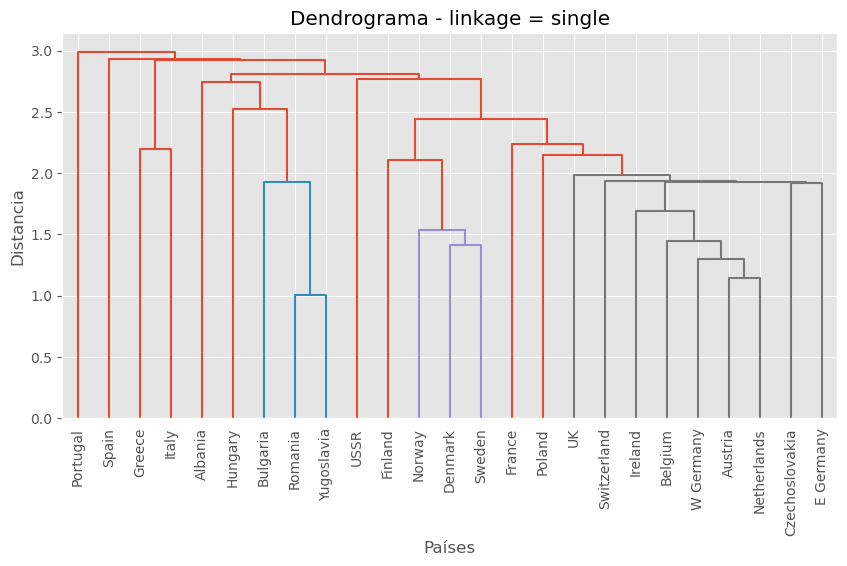

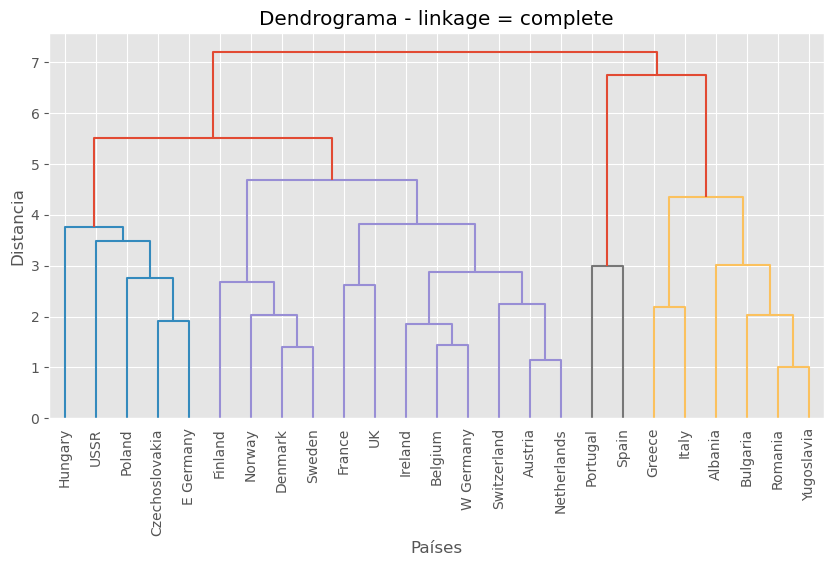

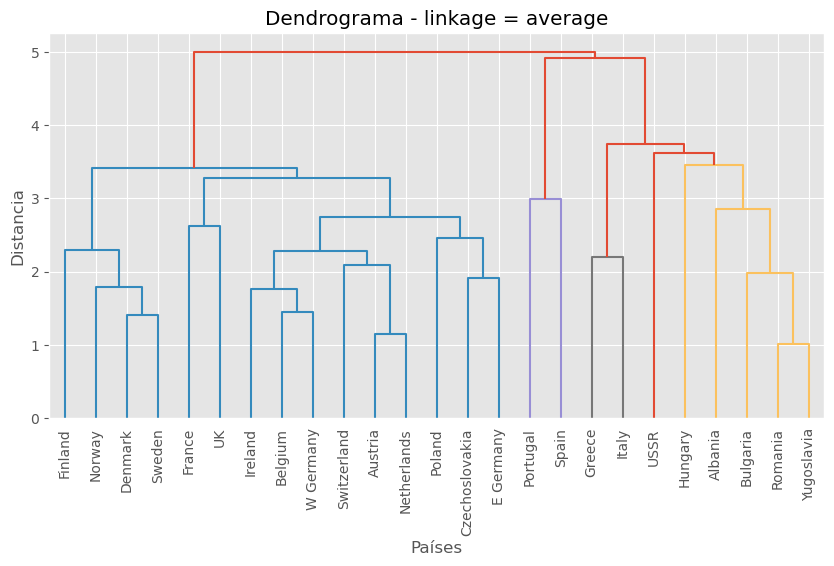

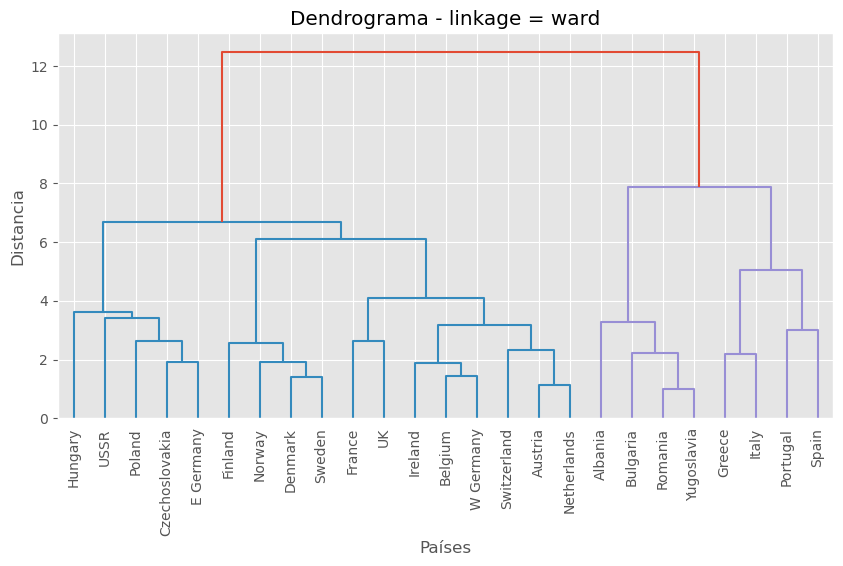

In [791]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage

# ==============================
# 1. Cargar datos
# ==============================
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Estandarizar variables numéricas
X = food_data.drop(columns=["Country"])
X_scaled = StandardScaler().fit_transform(X)

# ==============================
# 2. Función para graficar dendrograma
# ==============================
def plot_dendrogram(X, method):
    Z = linkage(X, method=method)
    plt.figure(figsize=(10, 5))
    dendrogram(Z, labels=food_data["Country"].values, leaf_rotation=90)
    plt.title(f"Dendrograma - linkage = {method}")
    plt.xlabel("Países")
    plt.ylabel("Distancia")
    plt.show()

# ==============================
# 3. Dibujar con distintos métodos
# ==============================
for method in ["single", "complete", "average", "ward"]:
    plot_dendrogram(X_scaled, method)

Qué hace el código:
- Dibuja el dendrograma con línea roja de corte.
- Usa fcluster para asignar países a clusters.
- Imprime en tabla los países y el cluster correspondiente.

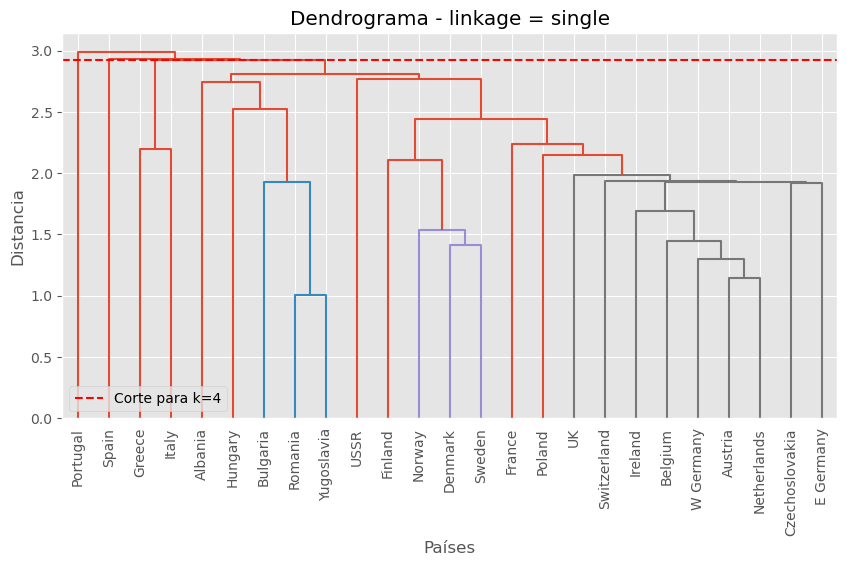


=== Asignación de clusters con linkage = single ===
       Country  Cluster
         Italy        1
        Greece        1
          USSR        2
            UK        2
   Switzerland        2
        Sweden        2
       Romania        2
        Poland        2
        Norway        2
   Netherlands        2
     W Germany        2
       Albania        2
       Hungary        2
        France        2
       Finland        2
     E Germany        2
       Denmark        2
Czechoslovakia        2
      Bulgaria        2
       Belgium        2
       Austria        2
       Ireland        2
    Yugoslavia        2
         Spain        3
      Portugal        4


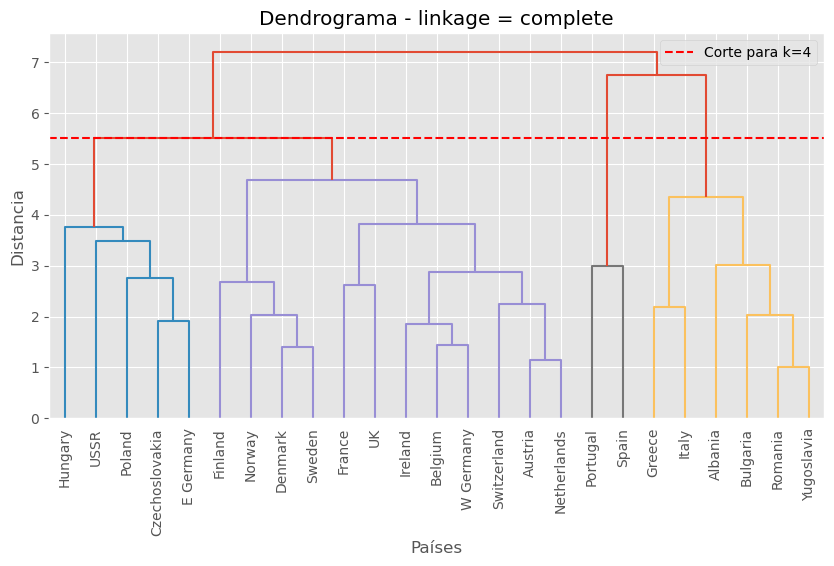


=== Asignación de clusters con linkage = complete ===
       Country  Cluster
        Poland        1
          USSR        1
Czechoslovakia        1
     E Germany        1
       Hungary        1
            UK        2
   Switzerland        2
        Norway        2
   Netherlands        2
     W Germany        2
       Ireland        2
        Sweden        2
        France        2
       Finland        2
       Denmark        2
       Belgium        2
       Austria        2
      Portugal        3
         Spain        3
       Albania        4
         Italy        4
        Greece        4
      Bulgaria        4
       Romania        4
    Yugoslavia        4


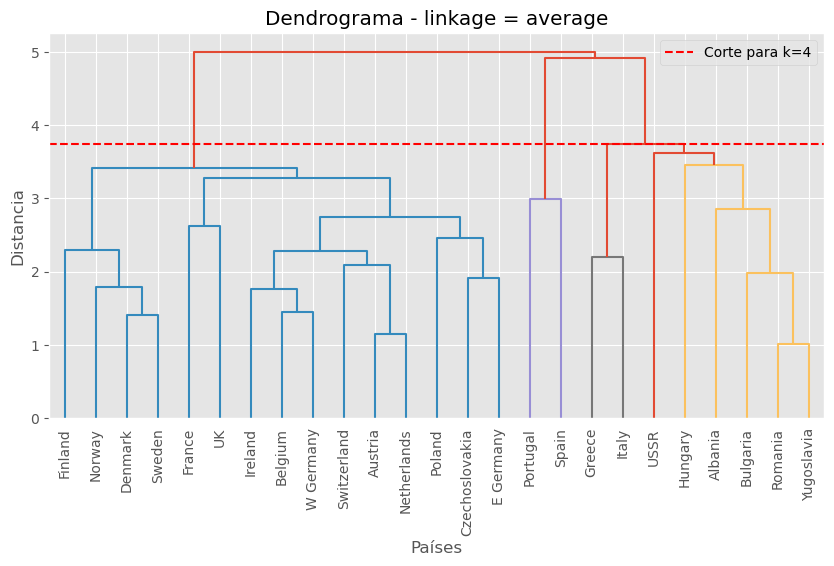


=== Asignación de clusters con linkage = average ===
       Country  Cluster
        Sweden        1
        Norway        1
   Netherlands        1
     W Germany        1
       Ireland        1
            UK        1
        Poland        1
        France        1
     E Germany        1
       Denmark        1
Czechoslovakia        1
   Switzerland        1
       Belgium        1
       Austria        1
       Finland        1
         Spain        2
      Portugal        2
         Italy        3
        Greece        3
          USSR        4
       Albania        4
       Hungary        4
      Bulgaria        4
       Romania        4
    Yugoslavia        4


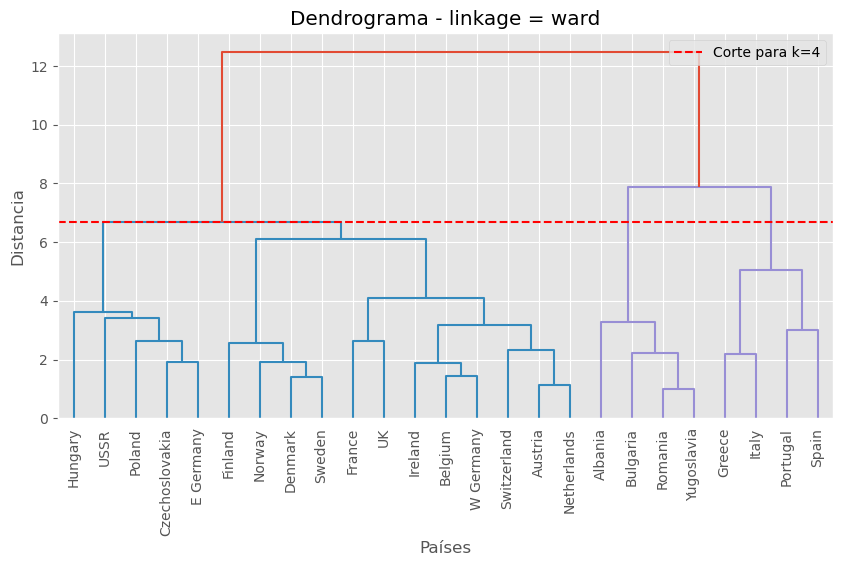


=== Asignación de clusters con linkage = ward ===
       Country  Cluster
        Poland        1
          USSR        1
Czechoslovakia        1
     E Germany        1
       Hungary        1
        France        2
        Norway        2
   Netherlands        2
     W Germany        2
       Ireland        2
        Sweden        2
   Switzerland        2
       Finland        2
       Denmark        2
       Belgium        2
       Austria        2
            UK        2
       Albania        3
    Yugoslavia        3
       Romania        3
      Bulgaria        3
      Portugal        4
        Greece        4
         Spain        4
         Italy        4


In [794]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# ==============================
# 1. Cargar datos
# ==============================
url = "https://raw.githubusercontent.com/fenago/datasets/main/protein.csv"
food_data = pd.read_csv(url)

# Estandarizar variables numéricas
X = food_data.drop(columns=["Country"])
X_scaled = StandardScaler().fit_transform(X)

# ==============================
# 2. Función para graficar dendrograma y asignar clusters
# ==============================
def plot_dendrogram_and_clusters(X, method, k=4):
    Z = linkage(X, method=method)
    
    # Graficar dendrograma
    plt.figure(figsize=(10, 5))
    dendrogram(Z, labels=food_data["Country"].values, leaf_rotation=90)
    plt.title(f"Dendrograma - linkage = {method}")
    plt.xlabel("Países")
    plt.ylabel("Distancia")
    plt.axhline(y=Z[-(k-1), 2], c='red', linestyle='--', label=f"Corte para k={k}")
    plt.legend()
    plt.show()
    
    # Asignar clusters
    clusters = fcluster(Z, k, criterion='maxclust')
    resultados = pd.DataFrame({
        "Country": food_data["Country"],
        "Cluster": clusters
    }).sort_values("Cluster")
    
    print(f"\n=== Asignación de clusters con linkage = {method} ===")
    print(resultados.to_string(index=False))

# ==============================
# 3. Ejecutar con varios métodos
# ==============================
for method in ["single", "complete", "average", "ward"]:
    plot_dendrogram_and_clusters(X_scaled, method, k=4)

#### DBSCAN

In [797]:
import pandas as pd

home_data = pd.read_csv('housing.csv', usecols = ['longitude', 'latitude', 'median_house_value'])
home_data.head()

,longitude,latitude,median_house_value
0,-122.23,37.88,452600.0
1,-122.22,37.86,358500.0
2,-122.24,37.85,352100.0
3,-122.25,37.85,341300.0
4,-122.25,37.85,342200.0


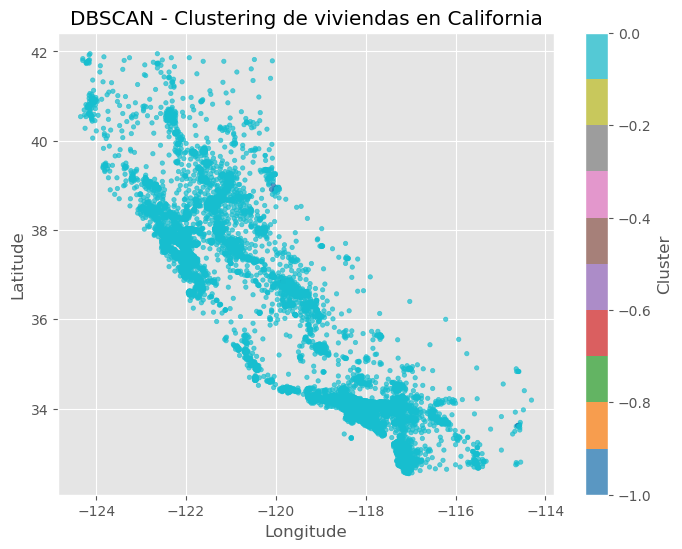

 0    20635
-1        5
Name: Cluster, dtype: int64


In [799]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Escogemos las features para clustering (ubicación geográfica + valor)
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalar datos (muy importante en DBSCAN)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Aplicar DBSCAN
# ==============================
dbscan = DBSCAN(eps=0.5, min_samples=10)  
# eps = radio de vecindad
# min_samples = mínimo de puntos para considerar un cluster
labels = dbscan.fit_predict(X_scaled)

# Guardar resultados en el DataFrame
home_data['Cluster'] = labels

# ==============================
# 3. Visualización
# ==============================
plt.figure(figsize=(8,6))
plt.scatter(home_data['longitude'], home_data['latitude'], 
            c=home_data['Cluster'], cmap='tab10', s=10, alpha=0.7)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("DBSCAN - Clustering de viviendas en California")
plt.colorbar(label="Cluster")
plt.show()

# ==============================
# 4. Revisar resultados
# ==============================
print(home_data['Cluster'].value_counts())

Explicación rápida:
- eps: radio de vecindad. Si es muy pequeño, tendrás muchos puntos como -1 (outliers). Si es grande, clusters se fusionan.
- min_samples: número mínimo de vecinos para formar un cluster.
- Cluster -1: significa ruido (puntos que DBSCAN no clasificó en ningún cluster).

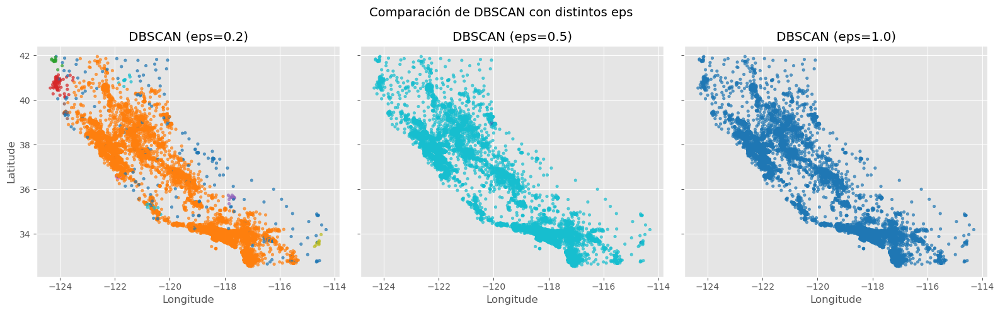

In [802]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Features para clustering
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalamos datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Probar varios valores de eps
# ==============================
eps_values = [0.2, 0.5, 1.0]

fig, axs = plt.subplots(1, len(eps_values), figsize=(16,5), sharex=True, sharey=True)

for i, eps in enumerate(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples=10)
    labels = dbscan.fit_predict(X_scaled)
    
    axs[i].scatter(home_data['longitude'], home_data['latitude'],
                   c=labels, cmap="tab10", s=10, alpha=0.7)
    axs[i].set_title(f"DBSCAN (eps={eps})")
    axs[i].set_xlabel("Longitude")
    if i == 0:
        axs[i].set_ylabel("Latitude")

plt.suptitle("Comparación de DBSCAN con distintos eps", fontsize=14)
plt.tight_layout()
plt.show()

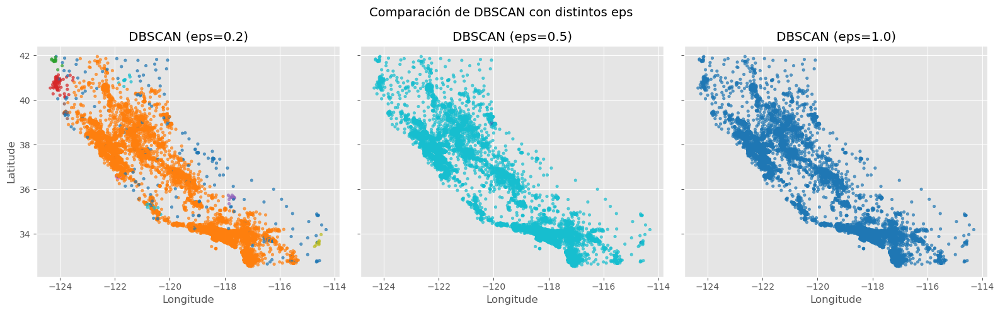

In [803]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Features para clustering
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalamos datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Probar varios valores de eps
# ==============================
eps_values = [0.2, 0.5, 1.0]

fig, axs = plt.subplots(1, len(eps_values), figsize=(16,5), sharex=True, sharey=True)

for i, eps in enumerate(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples=10)
    labels = dbscan.fit_predict(X_scaled)
    
    axs[i].scatter(home_data['longitude'], home_data['latitude'],
                   c=labels, cmap="tab10", s=10, alpha=0.7)
    axs[i].set_title(f"DBSCAN (eps={eps})")
    axs[i].set_xlabel("Longitude")
    if i == 0:
        axs[i].set_ylabel("Latitude")

plt.suptitle("Comparación de DBSCAN con distintos eps", fontsize=14)
plt.tight_layout()
plt.show()

🔎 ¿Qué hace este código?
- Aplica DBSCAN con tres valores de eps: 0.2, 0.5 y 1.0.
- Dibuja un mapa de clusters en coordenadas (longitude, latitude).
- Los puntos con color -1 son outliers (ruido) que DBSCAN no logró asignar a ningún cluster.

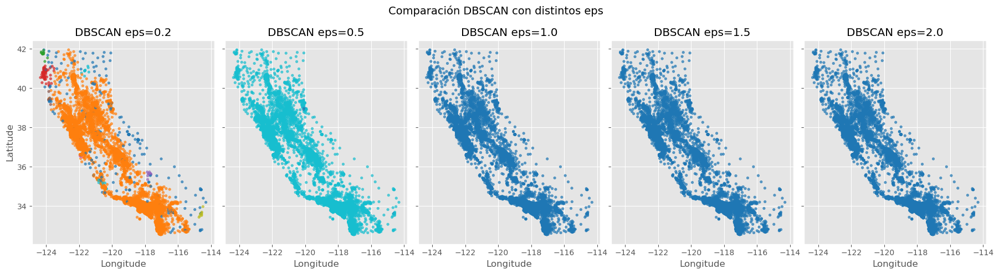

Resultados de Silhouette Score por eps:
eps=0.2: None
eps=0.5: None
eps=1.0: None
eps=1.5: None
eps=2.0: None


In [807]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Features para clustering
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalar datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Probar varios valores de eps
# ==============================
eps_values = [0.2, 0.5, 1.0, 1.5, 2.0]
silhouette_scores = {}

fig, axs = plt.subplots(1, len(eps_values), figsize=(18, 5), sharex=True, sharey=True)

for i, eps in enumerate(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples=10)
    labels = dbscan.fit_predict(X_scaled)
    
    # Guardar silhouette solo si hay más de 1 cluster
    if len(set(labels)) > 1 and -1 not in set(labels):
        score = silhouette_score(X_scaled, labels)
        silhouette_scores[eps] = score
    else:
        silhouette_scores[eps] = None
    
    # Gráfico
    axs[i].scatter(home_data['longitude'], home_data['latitude'],
                   c=labels, cmap="tab10", s=10, alpha=0.7)
    axs[i].set_title(f"DBSCAN eps={eps}")
    axs[i].set_xlabel("Longitude")
    if i == 0:
        axs[i].set_ylabel("Latitude")

plt.suptitle("Comparación DBSCAN con distintos eps", fontsize=14)
plt.tight_layout()
plt.show()

# ==============================
# 3. Resultados de Silhouette
# ==============================
print("Resultados de Silhouette Score por eps:")
for eps, score in silhouette_scores.items():
    print(f"eps={eps}: {score}")

Explicación:
- Visualización: ves cómo cambian los clusters al variar eps.
- Silhouette Score: mide la calidad de los clusters (1 es ideal, 0 significa clusters superpuestos, valores negativos son malos).
- Si DBSCAN detecta solo ruido o un único cluster, no se calcula el Silhouette (se queda en None).

Aquí tienes el código completo que además de aplicar DBSCAN y calcular los Silhouette Scores, dibuja la evolución del Silhouette en función de eps para identificar el mejor valor:

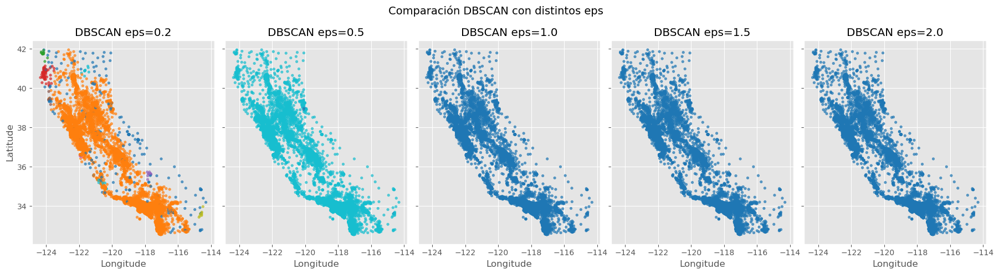

Resultados de Silhouette Score por eps:
eps=0.2: -0.46768540264778524
eps=0.5: 0.209334359647742
eps=1.0: None
eps=1.5: None
eps=2.0: None


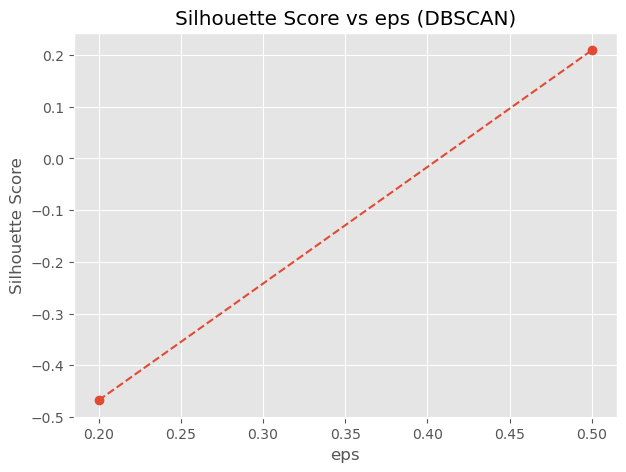

In [810]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Features para clustering
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalar datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Probar varios valores de eps
# ==============================
eps_values = [0.2, 0.5, 1.0, 1.5, 2.0]
silhouette_scores = {}

fig, axs = plt.subplots(1, len(eps_values), figsize=(18, 5), sharex=True, sharey=True)

for i, eps in enumerate(eps_values):
    dbscan = DBSCAN(eps=eps, min_samples=10)
    labels = dbscan.fit_predict(X_scaled)
    
    # Guardar silhouette solo si hay más de 1 cluster válido
    if len(set(labels)) > 1 and (set(labels) != {-1}):
        score = silhouette_score(X_scaled, labels)
        silhouette_scores[eps] = score
    else:
        silhouette_scores[eps] = None
    
    # Gráfico de clusters
    axs[i].scatter(home_data['longitude'], home_data['latitude'],
                   c=labels, cmap="tab10", s=10, alpha=0.7)
    axs[i].set_title(f"DBSCAN eps={eps}")
    axs[i].set_xlabel("Longitude")
    if i == 0:
        axs[i].set_ylabel("Latitude")

plt.suptitle("Comparación DBSCAN con distintos eps", fontsize=14)
plt.tight_layout()
plt.show()

# ==============================
# 3. Resultados de Silhouette
# ==============================
print("Resultados de Silhouette Score por eps:")
for eps, score in silhouette_scores.items():
    print(f"eps={eps}: {score}")

# ==============================
# 4. Gráfico Silhouette vs eps
# ==============================
eps_plot = [e for e in silhouette_scores if silhouette_scores[e] is not None]
scores_plot = [silhouette_scores[e] for e in eps_plot]

plt.figure(figsize=(7,5))
plt.plot(eps_plot, scores_plot, marker="o", linestyle="--")
plt.xlabel("eps")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score vs eps (DBSCAN)")
plt.show()

Qué obtendrás?
- Mapas de clusters con distintos valores de eps.
- Tabla con Silhouette Scores por cada eps.
- Gráfico línea Silhouette vs eps → fácil para ver cuál valor de eps logra mejor calidad de agrupación.

El k-dist plot es un método clásico para estimar el parámetro eps en DBSCAN.
La idea es:
- Calcular la distancia al k-ésimo vecino más cercano (normalmente k = min_samples, por ejemplo 10).
- Ordenar esas distancias.
- Buscar el "codo" del gráfico → allí suele estar el valor adecuado para eps.
- Aquí te dejo el código adaptado a tu base housing.csv:

El k-dist plot es un método clásico para estimar el parámetro eps en DBSCAN.
La idea es:
- Calcular la distancia al k-ésimo vecino más cercano (normalmente k = min_samples, por ejemplo 10).
- Ordenar esas distancias.
- Buscar el "codo" del gráfico → allí suele estar el valor adecuado para eps.
- Aquí te dejo el código adaptado a tu base housing.csv:

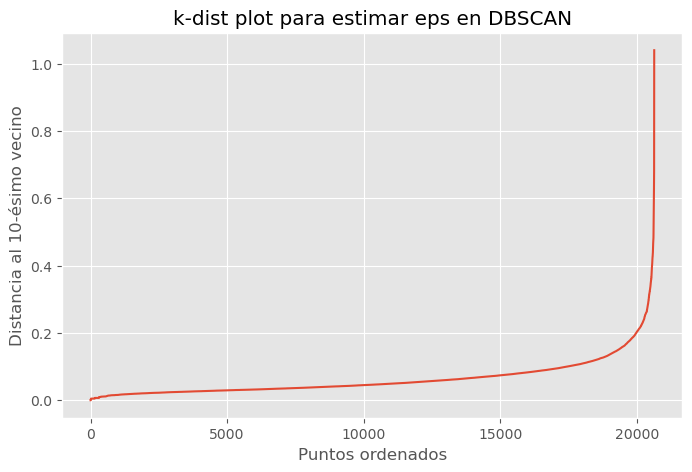

In [814]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Features para clustering
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalar datos
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Calcular distancias k-NN
# ==============================
k = 10  # igual a min_samples de DBSCAN
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

# Tomar la distancia al k-ésimo vecino (columna -1)
k_distances = distances[:, k-1]
k_distances = sorted(k_distances)

# ==============================
# 3. Graficar k-dist plot
# ==============================
plt.figure(figsize=(8,5))
plt.plot(k_distances)
plt.ylabel(f"Distancia al {k}-ésimo vecino")
plt.xlabel("Puntos ordenados")
plt.title("k-dist plot para estimar eps en DBSCAN")
plt.grid(True)
plt.show()

Cómo usar el gráfico:
- El gráfico es creciente y en algún punto verás un codo (elbow).
- Ese valor en el eje Y es un buen candidato para eps.
- Ejemplo: si el codo aparece cerca de 0.8, puedes probar eps=0.8 en DBSCAN.

Cómo usar el gráfico:
- El gráfico es creciente y en algún punto verás un codo (elbow).
- Ese valor en el eje Y es un buen candidato para eps.
- Ejemplo: si el codo aparece cerca de 0.8, puedes probar eps=0.8 en DBSCAN.

Entonces armemos un pipeline completo que:
- Calcula el eps sugerido a partir del k-dist plot.
- Ejecuta DBSCAN con ese eps.
- Evalúa con el Silhouette Score.
- Grafica los clusters encontrados (en 2D usando longitude y latitude).

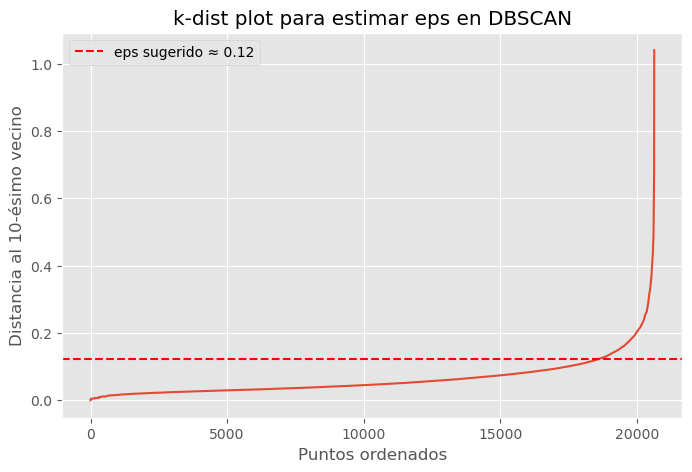

🔎 eps sugerido: 0.121
✅ Silhouette Score (sin ruido): -0.347


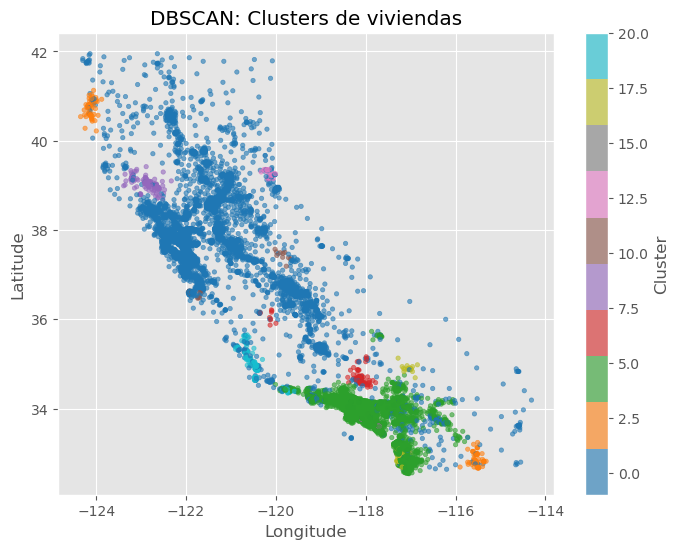

In [818]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv('housing.csv', usecols=['longitude', 'latitude', 'median_house_value'])

# Variables para clustering
X = home_data[['longitude', 'latitude', 'median_house_value']]

# Escalar
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==============================
# 2. Estimar eps con k-dist plot
# ==============================
k = 10  # valor típico igual a min_samples
neighbors = NearestNeighbors(n_neighbors=k)
neighbors_fit = neighbors.fit(X_scaled)
distances, indices = neighbors_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, k-1])  # distancias al k-ésimo vecino
eps_sugerido = np.percentile(k_distances, 90)  # heurística (puedes ajustar)

# Graficar k-dist plot
plt.figure(figsize=(8,5))
plt.plot(k_distances)
plt.axhline(y=eps_sugerido, color="r", linestyle="--", label=f"eps sugerido ≈ {eps_sugerido:.2f}")
plt.ylabel(f"Distancia al {k}-ésimo vecino")
plt.xlabel("Puntos ordenados")
plt.title("k-dist plot para estimar eps en DBSCAN")
plt.legend()
plt.grid(True)
plt.show()

print(f"🔎 eps sugerido: {eps_sugerido:.3f}")

# ==============================
# 3. Ejecutar DBSCAN
# ==============================
dbscan = DBSCAN(eps=eps_sugerido, min_samples=k)
clusters = dbscan.fit_predict(X_scaled)

home_data['Cluster'] = clusters

# ==============================
# 4. Evaluación con Silhouette
# ==============================
# Filtrar ruido (-1)
mask = clusters != -1
if len(set(clusters[mask])) > 1:  # al menos 2 clusters válidos
    score = silhouette_score(X_scaled[mask], clusters[mask])
    print(f"✅ Silhouette Score (sin ruido): {score:.3f}")
else:
    print("⚠️ No se pudo calcular Silhouette Score (solo 1 cluster encontrado).")

# ==============================
# 5. Graficar clusters en mapa
# ==============================
plt.figure(figsize=(8,6))
plt.scatter(
    home_data['longitude'], home_data['latitude'],
    c=home_data['Cluster'], cmap="tab10", s=10, alpha=0.6
)
plt.colorbar(label="Cluster")
plt.title("DBSCAN: Clusters de viviendas")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Explicación rápida:
- eps se calcula con el percentil 90 del k-dist plot. (Puedes ajustar al 85, 95, etc.)
- Se aplica DBSCAN con min_samples = k.
- Se filtran los puntos de ruido (Cluster = -1).
 -Si hay más de un cluster válido → se calcula el Silhouette Score.

Explicación rápida:
- eps se calcula con el percentil 90 del k-dist plot. (Puedes ajustar al 85, 95, etc.)
- Se aplica DBSCAN con min_samples = k.
- Se filtran los puntos de ruido (Cluster = -1).
- Si hay más de un cluster válido → se calcula el Silhouette Score.

A continuación:  Te preparo ahora un mapa comparativo donde se distinguen:
Los clusters encontrados por DBSCAN (colores distintos).
El ruido (-1) en color gris oscuro.

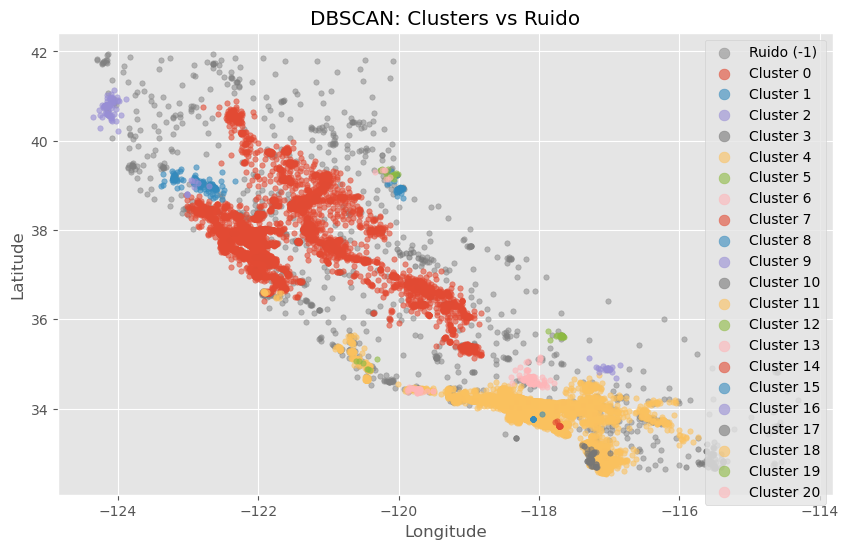

In [826]:
import matplotlib.pyplot as plt

# ==============================
# 6. Graficar clusters y ruido
# ==============================
plt.figure(figsize=(10,6))

# Puntos de ruido
plt.scatter(
    home_data.loc[home_data['Cluster'] == -1, 'longitude'],
    home_data.loc[home_data['Cluster'] == -1, 'latitude'],
    c="gray", s=15, alpha=0.5, label="Ruido (-1)"
)

# Puntos de cada cluster
for c in set(home_data['Cluster']):
    if c != -1:
        plt.scatter(
            home_data.loc[home_data['Cluster'] == c, 'longitude'],
            home_data.loc[home_data['Cluster'] == c, 'latitude'],
            s=15, alpha=0.6, label=f"Cluster {c}"
        )

plt.title("DBSCAN: Clusters vs Ruido")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(markerscale=2)
plt.show()

Esto te genero un mapa comparativo donde:
- El ruido aparece en gris.
- Los clusters en colores distintos.
- La leyenda indica qué es ruido y qué cluster corresponde.

Esto te genera un mapa comparativo donde:
El ruido aparece en gris.
Los clusters en colores distintos.
La leyenda indica qué es ruido y qué cluster corresponde.

Número de observaciones por cluster:

-1      1163
 0      8074
 1        46
 2       100
 3        90
 4     10524
 5        19
 6       102
 7        10
 8       113
 9        10
 10       10
 11       14
 12       17
 13        7
 14       14
 15       11
 16       25
 17       52
 18      194
 19        7
 20       38
Name: Cluster, dtype: int64

Tabla resumen:
    Cluster  Cantidad
0        -1      1163
1         0      8074
2         1        46
3         2       100
4         3        90
5         4     10524
6         5        19
7         6       102
8         7        10
9         8       113
10        9        10
11       10        10
12       11        14
13       12        17
14       13         7
15       14        14
16       15        11
17       16        25
18       17        52
19       18       194
20       19         7
21       20        38


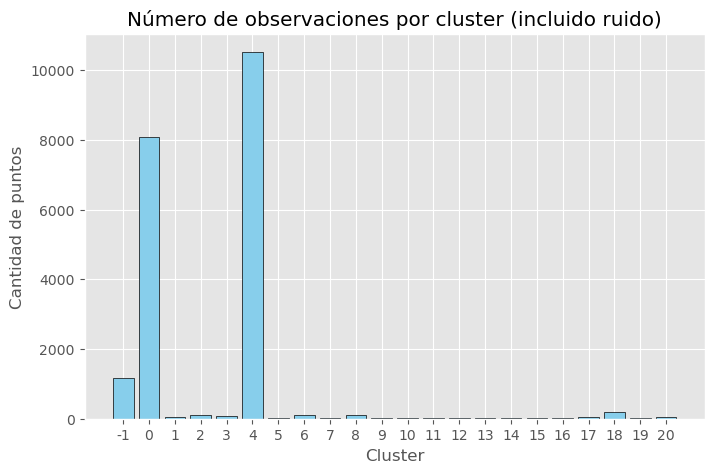

In [830]:
# ==============================
# 7. Resumen de observaciones por cluster
# ==============================
resumen_clusters = home_data['Cluster'].value_counts().sort_index()
print("Número de observaciones por cluster:\n")
print(resumen_clusters)

# Convertir en DataFrame para más claridad
resumen_df = resumen_clusters.reset_index()
resumen_df.columns = ['Cluster', 'Cantidad']

import pandas as pd
import matplotlib.pyplot as plt

# Mostrar tabla
print("\nTabla resumen:")
print(resumen_df)

# ==============================
# 8. Gráfico de barras
# ==============================
plt.figure(figsize=(8,5))
plt.bar(resumen_df['Cluster'].astype(str), resumen_df['Cantidad'], color="skyblue", edgecolor="black")
plt.title("Número de observaciones por cluster (incluido ruido)")
plt.xlabel("Cluster")
plt.ylabel("Cantidad de puntos")
plt.show()

Con esto tendrás:
- Tabla resumen con la cantidad de puntos en cada cluster (ej: Cluster -1 = ruido).
- Gráfico de barras para comparar el tamaño de cada cluster.

A continuacion calculemos un mapa de calor de la variable median_house_value promedio por cluster para ver cómo cambia el valor de las casas en cada grupo?

Promedio de median_house_value por cluster:

    Cluster  median_house_value
0        -1       183263.208083
1         0       195722.930518
2         1       108452.173913
3         2        84591.000000
4         3        75458.888889
5         4       222568.668377
6         5        90042.105263
7         6       124927.450980
8         7        59660.000000
9         8        96598.230088
10        9       137380.000000
11       10       110820.000000
12       11       285607.142857
13       12       152194.117647
14       13       177871.428571
15       14        76028.571429
16       15        59954.545455
17       16        67940.000000
18       17       498477.750000
19       18       170637.113402
20       19       274457.142857
21       20       339568.421053


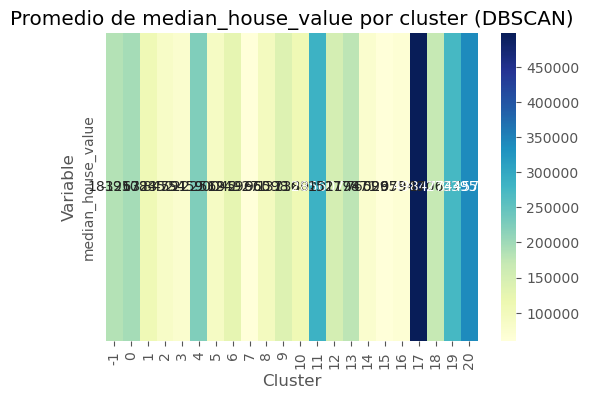

In [834]:
import seaborn as sns
import matplotlib.pyplot as plt

# ==============================
# 9. Promedio de median_house_value por cluster
# ==============================
cluster_means = home_data.groupby("Cluster")["median_house_value"].mean().reset_index()

print("Promedio de median_house_value por cluster:\n")
print(cluster_means)

# ==============================
# 10. Heatmap
# ==============================
plt.figure(figsize=(6,4))
sns.heatmap(cluster_means.set_index("Cluster").T, annot=True, cmap="YlGnBu", fmt=".0f")
plt.title("Promedio de median_house_value por cluster (DBSCAN)")
plt.ylabel("Variable")
plt.xlabel("Cluster")
plt.show()

Este heatmap te mostrará:
- Columnas = clusters (incluido -1 = ruido)
- Valores = promedio de median_house_value en cada cluster
- Así puedes ver rápidamente qué grupos tienen viviendas más caras o más baratas.

Vamos a hacer un mapa geográfico de los clusters detectados por DBSCAN usando las columnas longitude y latitude.

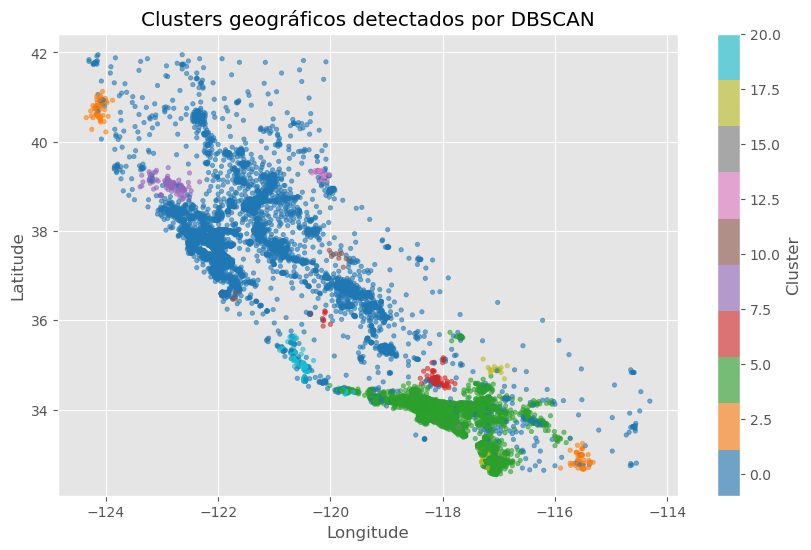

In [838]:
import matplotlib.pyplot as plt

# ==============================
# 11. Mapa geográfico de clusters
# ==============================
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    home_data["longitude"], 
    home_data["latitude"], 
    c=home_data["Cluster"], 
    cmap="tab10", 
    s=10, 
    alpha=0.6
)

plt.colorbar(scatter, label="Cluster")
plt.title("Clusters geográficos detectados por DBSCAN")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

A continuacion un mapa con un coloreado por median_house_value (en lugar de cluster), para comparar cómo se relaciona el precio de las viviendas con los grupos detectados?

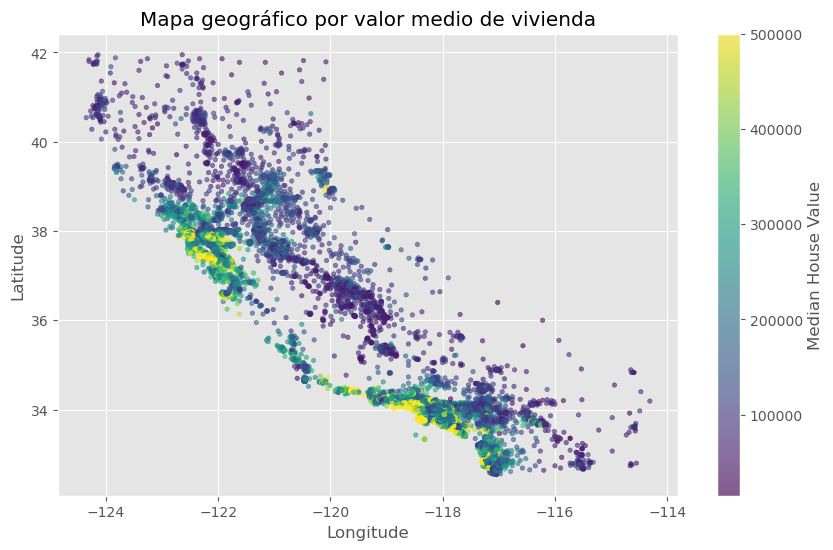

In [841]:
import matplotlib.pyplot as plt

# ==============================
# 12. Mapa geográfico por valor medio de vivienda
# ==============================
plt.figure(figsize=(10, 6))
scatter = plt.scatter(
    home_data["longitude"], 
    home_data["latitude"], 
    c=home_data["median_house_value"], 
    cmap="viridis", 
    s=10, 
    alpha=0.6
)

plt.colorbar(scatter, label="Median House Value")
plt.title("Mapa geográfico por valor medio de vivienda")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

Un mapa en escala de colores (viridis) donde los tonos representan el valor medio de las casas.
Puedes comparar este gráfico con el de los clusters DBSCAN y notar si el algoritmo separó bien las zonas de alto y bajo valor.

Vamos a ponerle un mapa base real para que los clusters de DBSCAN se ubiquen sobre un mapa geográfico de California.
Lo más sencillo es usar contextily con coordenadas en proyección métrica (Web Mercator: EPSG:3857).
Te paso el código paso a paso:

In [845]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import folium

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv("housing.csv", usecols=["longitude", "latitude", "median_house_value"])

# ==============================
# 2. Escalar para DBSCAN
# ==============================
scaler = StandardScaler()
X = scaler.fit_transform(home_data[['longitude', 'latitude']])

# ==============================
# 3. DBSCAN
# ==============================
dbscan = DBSCAN(eps=0.3, min_samples=50)
clusters = dbscan.fit_predict(X)
home_data["cluster"] = clusters

# ==============================
# 4. Crear mapa interactivo
# ==============================
# Centro aproximado de California
m = folium.Map(location=[37, -119], zoom_start=6, tiles="CartoDB positron")

# Colores distintos por cluster
colors = {
    -1: "black",   # ruido
    0: "red",
    1: "blue",
    2: "green",
    3: "purple",
    4: "orange"
}

# Añadir puntos al mapa
for _, row in home_data.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=2,
        color=colors.get(row["cluster"], "gray"),
        fill=True,
        fill_opacity=0.6
    ).add_to(m)

# Mostrar mapa
m

In [848]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import folium

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv("housing.csv", usecols=["longitude", "latitude", "median_house_value"])

# ==============================
# 2. Escalar coordenadas
# ==============================
scaler = StandardScaler()
X = scaler.fit_transform(home_data[['longitude', 'latitude']])

# ==============================
# 3. Ajustar DBSCAN
# ==============================
dbscan = DBSCAN(eps=0.3, min_samples=50)  # puedes ajustar eps y min_samples
clusters = dbscan.fit_predict(X)
home_data["cluster"] = clusters

# ==============================
# 4. Crear mapa interactivo
# ==============================
# Centro aproximado de California
m = folium.Map(location=[37, -119], zoom_start=6, tiles="CartoDB positron")

# Colores para clusters
colors = {
    -1: "black",   # ruido
    0: "red",
    1: "blue",
    2: "green",
    3: "purple",
    4: "orange",
    5: "brown"
}

# Añadir puntos al mapa
for _, row in home_data.iterrows():
    folium.CircleMarker(
        location=[row["latitude"], row["longitude"]],
        radius=2,
        color=colors.get(row["cluster"], "gray"),
        fill=True,
        fill_opacity=0.6
    ).add_to(m)

# ==============================
# 5. Mostrar mapa
# ==============================
m

en este mapa lo puedes mover con el mouse, hacer zoom in/out y explorar dónde están los clusters que encontró DBSCAN.
🔹 Los puntos negros (-1) son considerados ruido (outliers) por el algoritmo.

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
import folium

# ==============================
# 1. Cargar datos
# ==============================
home_data = pd.read_csv("housing.csv", usecols=["longitude", "latitude", "median_house_value"])

# ==============================
# 2. Escalar coordenadas
# ==============================
scaler = StandardScaler()
X = scaler.fit_transform(home_data[['longitude', 'latitude']])

# ==============================
# 3. Ajustar DBSCAN
# ==============================
dbscan = DBSCAN(eps=0.3, min_samples=50)
clusters = dbscan.fit_predict(X)
home_data["cluster"] = clusters

# ==============================
# 4. Crear mapa base
# ==============================
m = folium.Map(location=[37, -119], zoom_start=6, tiles="CartoDB positron")

# ==============================
# 5. Crear capas por cluster
# ==============================
unique_clusters = sorted(home_data["cluster"].unique())
colors = [
    "red", "blue", "green", "purple", "orange", "brown", 
    "pink", "cadetblue", "darkgreen", "lightred"
]

for idx, cluster_id in enumerate(unique_clusters):
    if cluster_id == -1:
        layer_name = "Ruido (-1)"
        color = "black"
    else:
        layer_name = f"Cluster {cluster_id}"
        color = colors[idx % len(colors)]

    fg = folium.FeatureGroup(name=layer_name)

    cluster_points = home_data[home_data["cluster"] == cluster_id]

    for _, row in cluster_points.iterrows():
        popup_text = f"""
        Cluster: {cluster_id}<br>
        Valor medio casa: ${row['median_house_value']:,.0f}<br>
        Lat: {row['latitude']:.4f}, Lon: {row['longitude']:.4f}
        """
        folium.CircleMarker(
            location=[row["latitude"], row["longitude"]],
            radius=2,
            color=color,
            fill=True,
            fill_opacity=0.6,
            popup=folium.Popup(popup_text, max_width=250)
        ).add_to(fg)

    fg.add_to(m)

# ==============================
# 6. Control de capas
# ==============================
folium.LayerControl().add_to(m)

# ==============================
# 7. Mostrar mapa
# ==============================
m

Ahora al hacer click en un punto, verás:
El número de cluster al que pertenece
El valor medio de la casa (median_house_value)
Las coordenadas (lat, lon)

Vamos a construir un resumen por cluster que muestre:
Número de cluster
Cantidad de viviendas en ese cluster
Valor medio de la vivienda en ese cluster
Aquí tienes el código en Python:

Vamos a construir un resumen por cluster que muestre:
Número de cluster
Cantidad de viviendas en ese cluster
Valor medio de la vivienda en ese cluster
Aquí tienes el código en Python:

In [861]:
# ==============================
# 8. Resumen por cluster
# ==============================
resumen = (
    home_data.groupby("cluster")
    .agg(
        cantidad_viviendas=("median_house_value", "count"),
        valor_medio_vivienda=("median_house_value", "mean")
    )
    .sort_index()
)

# Mostrar resumen
import numpy as np
resumen["valor_medio_vivienda"] = resumen["valor_medio_vivienda"].apply(lambda x: f"${x:,.0f}")
resumen

,cantidad_viviendas,valor_medio_vivienda
cluster,,
-1,66,"$74,638"
0,20574,"$207,280"
